<div dir="rtl" style="text-align: right;">

# **פרויקט מסכם למידת מכונה**



<div dir="rtl" style="text-align: right;">

<h2>תוכן עניינים – ניווט בפרויקט</h2>

<p>
המחברת מסודרת לפי סעיפי המטלה.
לחיצה על שם סעיף מעבירה ישירות
לחלק המתאים במחברת.
</p>

<ol>
<li><a href="#scrollTo=JfI3gcidd8zd&line=3&uniqifier=1">סקירה כללית ומטרת הפרויקט</a></li>
<li><a href="#scrollTo=Za9uP_4QfAH-&line=5&uniqifier=1">נתוני הקלט, חקירת הנתונים ואסטרטגיה לפי גיל</a></li>
<li><a href="#scrollTo=cNJFx4ydlxPE&line=3&uniqifier=1">דרישות טכניות – הכנת הנתונים, המודלים והערכתם</a></li>
<li><a href="#scrollTo=AO49IG4MetUC">הנדסת פיצ'רים (Feature Engineering)</a></li>
<li><a href="#scrollTo=4huqg6e_tc2t&line=5&uniqifier=1">עקומת מורכבות (Complexity Curve)</a></li>
<li><a href="#scrollTo=LlFe69nHt9Wh&line=4&uniqifier=1">ניתוח שגיאות (Error Analysis)</a></li>
<li><a href="#scrollTo=TXC8UBBqwAUW&line=2&uniqifier=1">ניתוח הוגנות (Fairness Analysis)</a></li>
<li><a href="#scrollTo=S5RptngNxhFI&line=4&uniqifier=1">בדיקות חיזוי על נתונים חדשים</a></li>
<li><a href="#scrollTo=vO7XZ6_pyDR8&line=3&uniqifier=1">דוח הפרויקט</a></li>
<li><a href="#scrollTo=mvjn1lCQyhKr&line=3&uniqifier=1">דרישות וקובצי ההגשה</a></li>
</ol>

<p>
ניתן לנווט בין תתי-הסעיפים גם באמצעות
תוכן העניינים המובנה בסרגל השמאלי של Google Colab.
</p>

</div>


<div dir="rtl" style="text-align: right;">

# **1. סקירה כללית - בניית מודל לחיזוי עלות תביעות בביטוח רכב**

<div dir="rtl" style="text-align: right;">

**מטרת הפרויקט:**

בפרויקט זה נבנה מודל למידת מכונה שמטרתו לחזות את עלות התביעות השנתית הצפויה של נהג עבור חברת ביטוח רכב.

המודל יתבסס על נתונים הידועים לחברת הביטוח לפני תחילת שנת הפוליסה, כגון גיל הנהג, ניסיון הנהיגה, מאפייני הרכב והרגלי השימוש בו.

**משתנה המטרה (Target):** `annual_claim_cost` - סך עלות התביעות של הנהג בשנת הפוליסה, בשקלים.

במהלך העבודה נחקור את הנתונים, נבצע עיבוד מקדים והנדסת פיצ'רים, נבנה מודלים מסוג Elastic Net ו-Random Forest ונעריך את ביצועיהם באמצעות Cross Validation.

בנוסף, ננתח את שגיאות החיזוי, נבחן את ביצועי המודל בקבוצות שונות ונקפיד על מניעת Data Leakage.


<div dir="rtl" style="text-align: right;">

### **ייבוא ספריות:**

In [6]:

# ייבוא ספריות לעבודה עם נתונים וליצירת גרפים
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# הגדרות תצוגה
pd.set_option('display.max_columns', None)

# הגדרת סגנון הגרפים
sns.set_theme(style='whitegrid')


<div dir="rtl" style="text-align: right;">


# **2. נתוני הקלט ומשתנה המטרה**


In [7]:

# העלאת קובץ הנתונים מהמחשב
from google.colab import files

uploaded = files.upload()

# קריאת הקובץ לתוך DataFrame
df = pd.read_csv('dataset_class.csv')

# הצגת ממדי הדאטה
print("Dataset shape:", df.shape)

# הצגת חמש השורות הראשונות
df.head()


Saving dataset_class.csv to dataset_class (2).csv
Dataset shape: (45000, 30)


,customer_id_hash,agent_code,country,area_type,region_density,winter_severity,driver_age,gender,marital_status,license_years,prior_claims_5y,no_claims_years,violations_3y,vehicle_type,vehicle_age,engine_hp,vehicle_value,safety_features_count,has_telematics,usage_type,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,current_premium,claim_count,at_fault,days_to_settlement,police_report_filed,annual_claim_cost
0,6db089eb,A043,ES,suburban,855,1.3,75,F,widowed,54,2.0,0,0,suv,11,182,51000,2,0,leisure,7500.0,5,15,lot,4450,1,0.0,27.0,0.0,6178
1,d3a860d7,A057,GB,suburban,1225,2.7,76,M,married,45,0.0,12,0,sedan,3,94,56500,5,1,leisure,3000.0,25,10,street,1630,0,NaN,NaN,NaN,0
2,f0610253,A186,IL,suburban,1651,1.9,60,M,single,42,0.0,8,0,small,11,90,19500,3,0,commute,12500.0,0,5,garage,980,0,NaN,NaN,NaN,0
3,3137c022,A002,JP,urban,5441,7.7,55,M,divorced,34,1.0,2,0,sedan,6,151,37500,5,0,commute,10000.0,5,5,street,1810,0,NaN,NaN,NaN,0
4,a1513621,A028,FR,urban,3231,5.9,69,M,widowed,51,4.0,1,1,sedan,2,142,86000,7,0,leisure,NaN,5,40,street,12290,0,NaN,NaN,NaN,0


<div dir="rtl" style="text-align: right;">


### **חקירת מבני הנתונים (EDA - Exploratory Data Analysis):**

In [8]:

# בדיקת מבנה הנתונים וסוגי המשתנים
df.info()

# בדיקת כמות ואחוז הערכים החסרים בכל עמודה
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

# מיון העמודות לפי אחוז הערכים החסרים
missing_values = missing_values.sort_values(
    by='Missing Percentage', ascending=False
)

display(missing_values)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id_hash       45000 non-null  object 
 1   agent_code             45000 non-null  object 
 2   country                45000 non-null  object 
 3   area_type              45000 non-null  object 
 4   region_density         45000 non-null  int64  
 5   winter_severity        45000 non-null  float64
 6   driver_age             45000 non-null  int64  
 7   gender                 45000 non-null  object 
 8   marital_status         45000 non-null  object 
 9   license_years          45000 non-null  int64  
 10  prior_claims_5y        41858 non-null  float64
 11  no_claims_years        45000 non-null  int64  
 12  violations_3y          45000 non-null  int64  
 13  vehicle_type           45000 non-null  object 
 14  vehicle_age            45000 non-null  int64  
 15  en

,Missing Count,Missing Percentage
at_fault,29207,64.90
police_report_filed,29207,64.90
days_to_settlement,29207,64.90
annual_km_estimated,4311,9.58
prior_claims_5y,3142,6.98
customer_id_hash,0,0.00
winter_severity,0,0.00
driver_age,0,0.00
marital_status,0,0.00
gender,0,0.00



<div dir="rtl" style="text-align: right;">

**<h3>בדיקת מבנה הנתונים</h3>**

<p>
בשלב הראשון בחנו את מבנה הנתונים, סוגי המשתנים
וכמות הערכים החסרים בכל עמודה.
</p>

<p>
מערך הנתונים מכיל <b>45,000 תצפיות ו-30 משתנים</b>.
כל תצפית מייצגת נהג בשנת פוליסה אחת.
</p>

**<h4>ממצאים עיקריים:</h4>**

<ul>
<li>
בעמודה <code>prior_claims_5y</code> נמצאו
3,142 ערכים חסרים (6.98%).
</li>

<li>
בעמודה <code>annual_km_estimated</code> נמצאו
4,311 ערכים חסרים (9.58%).
</li>

<li>
בעמודות <code>at_fault</code>,
<code>days_to_settlement</code> ו-
<code>police_report_filed</code>
נמצאו 29,207 ערכים חסרים בכל אחת (64.90%).
לפי מילון השדות, אלו נתונים הקשורים לתביעות
במהלך שנת הביטוח.
</li>

<li>
המשתנה <code>vehicle_value</code> מזוהה כ-
<code>object</code> ולא כמשתנה מספרי,
ולכן בהמשך נבדוק כיצד להמיר אותו לערכים מספריים.
</li>
</ul>

**<h4>מסקנות ראשוניות:</h4>**

<p>
חלק מהמשתנים מכילים ערכים חסרים, ולכן יהיה
צורך לטפל בהם בשלב העיבוד המקדים.
את השלמת הערכים נבצע בתוך ה-Pipeline
כדי למנוע Data Leakage במהלך Cross Validation.
</p>

<p>
בנוסף, מאחר שמטרת המודל היא לחזות את עלות
התביעות לפני תחילת הפוליסה, לא נשתמש
כפיצ'רים במשתנים שמתארים אירועים שהתרחשו
במהלך שנת הביטוח.
</p>

<p>
בשלב זה אנו חוקרים את הנתונים בלבד,
ללא שינוי או מחיקה של תצפיות.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **סטטיסטיקה תיאורית של הנתונים (Descriptive Statistics):**

In [9]:

# הצגת סטטיסטיקה תיאורית של המשתנים המספריים
df.describe().T


,count,mean,std,min,25%,50%,75%,max
region_density,45000.0,1886.716311,2161.133202,4.0,498.0,1151.0,2593.0,20000.0
winter_severity,45000.0,3.459389,2.214855,0.0,1.7,3.3,5.0,10.0
driver_age,45000.0,48.010511,16.613355,18.0,35.0,47.0,60.0,90.0
license_years,45000.0,28.853867,16.866459,0.0,15.0,28.0,41.0,95.0
prior_claims_5y,41858.0,1.039706,1.384058,0.0,0.0,1.0,2.0,6.0
no_claims_years,45000.0,6.750933,8.101940,0.0,1.0,3.0,10.0,30.0
violations_3y,45000.0,0.416467,0.717039,0.0,0.0,0.0,1.0,6.0
vehicle_age,45000.0,7.638844,5.313188,0.0,4.0,6.0,10.0,25.0
engine_hp,45000.0,143.920800,66.350986,12.0,94.0,137.0,178.0,650.0
safety_features_count,45000.0,3.983378,2.028846,0.0,2.0,4.0,6.0,8.0


<div dir="rtl" style="text-align: right;">


## <span dir="rtl" style="display:block; text-align:right;">**2.1 חקירת משתנה המטרה (Target Analysis)**</span>





<div dir="rtl" style="text-align: right;">

<p>
משתנה המטרה בפרויקט הוא <code>annual_claim_cost</code>,
המייצג את עלות התביעות השנתית של הנהג בשקלים.
</p>

</div>


Mean claim cost: 3050.84
Median claim cost: 0.0
Standard deviation: 7551.85
Drivers with zero claim cost: 64.9 %
Expensive drivers: 9.24 %


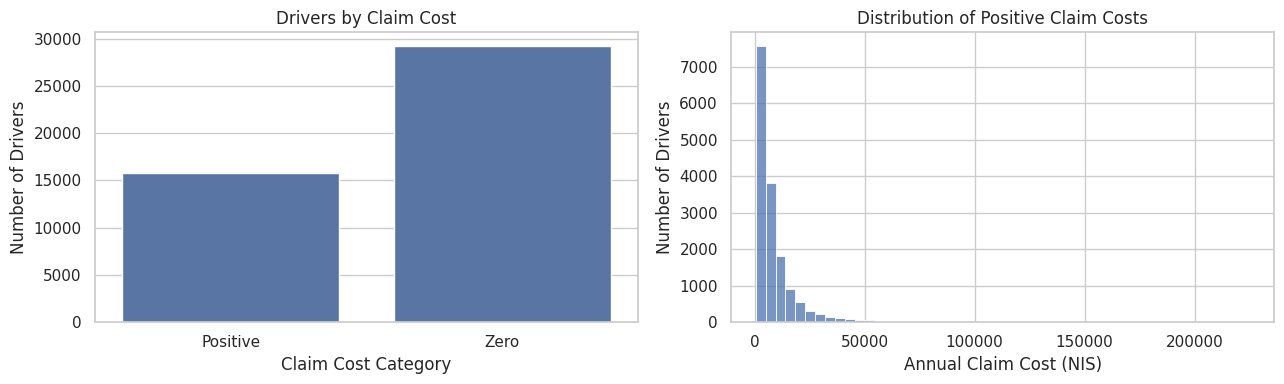

In [10]:

# הגדרת משתנה המטרה
target = df['annual_claim_cost']

# חישוב מדדים מרכזיים
print("Mean claim cost:", round(target.mean(), 2))
print("Median claim cost:", round(target.median(), 2))
print("Standard deviation:", round(target.std(), 2))

# חישוב שיעור הנהגים ללא תביעות
zero_pct = (target == 0).mean() * 100
print("Drivers with zero claim cost:", round(zero_pct, 2), "%")

# חישוב שיעור הנהגים היקרים
expensive_pct = (target > 10000).mean() * 100
print("Expensive drivers:", round(expensive_pct, 2), "%")

# יצירת גרפים
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# גרף 1: נהגים עם וללא עלות תביעות
sns.countplot(
    x=(target > 0).map({False: 'Zero', True: 'Positive'}),
    ax=axes[0]
)
axes[0].set_title('Drivers by Claim Cost')
axes[0].set_xlabel('Claim Cost Category')
axes[0].set_ylabel('Number of Drivers')

# גרף 2: התפלגות עלויות תביעות חיוביות
sns.histplot(
    target[target > 0],
    bins=50,
    ax=axes[1]
)
axes[1].set_title('Distribution of Positive Claim Costs')
axes[1].set_xlabel('Annual Claim Cost (NIS)')
axes[1].set_ylabel('Number of Drivers')

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">

### **ניתוח התפלגות משתנה המטרה (annual_claim_cost):**


<div dir="rtl" style="text-align: right;">


<p>
בחנו את התפלגות עלות התביעות השנתית של הנהגים
באמצעות מדדים סטטיסטיים וגרפים.
</p>

**<h4>ממצאים עיקריים:</h4>**

<ul>
<li>
עלות התביעות הממוצעת היא 3,050.84 ש"ח,
בעוד שהחציון הוא 0 ש"ח.
</li>

<li>
64.9% מהנהגים לא גרמו לעלויות תביעות במהלך שנת הפוליסה.
</li>

<li>
9.24% מהנהגים מוגדרים כנהגים יקרים,
כלומר עלות התביעות שלהם גבוהה מ-10,000 ש"ח.
</li>

<li>
סטיית התקן היא 7,551.85 ש"ח,
נתון המעיד על שונות גבוהה בעלויות התביעות.
</li>
</ul>

**<h4>מסקנות:</h4>**

<p>
מהגרפים ניתן לראות שהתפלגות עלויות התביעות
מוטה מאוד ימינה (Right-Skewed).
מרבית הנהגים אינם גורמים לעלויות כלל,
או גורמים לעלויות נמוכות יחסית,
בעוד שמספר קטן של נהגים גורם לעלויות גבוהות במיוחד.
</p>

<p>
הפער הגדול בין הממוצע לחציון, יחד עם סטיית התקן
הגבוהה, מעידים על כך שחיזוי עלות התביעות
עשוי להיות מאתגר.
</p>

<p>
בנוסף, תביעות בעלות גבוהה עלולות להשפיע
באופן משמעותי על מדדי שגיאה כמו RMSE,
המעניק משקל גבוה יותר לשגיאות גדולות.
</p>

<p>
בשלב זה לא נסיר תצפיות חריגות ולא נשנה
את משתנה המטרה, מכיוון שגם תביעות יקרות
הן חלק מהבעיה העסקית שהמודל נדרש לחזות.
</p>

</div>


<div dir="rtl" style="text-align: right;">


## <span dir="rtl" style="display:block; text-align:right;">**2.2 בחירת משתנים ומניעת דליפת מידע (Data Leakage)**</span>



<div dir="rtl" style="text-align: right;">


<p>
לפני בניית המודלים, נבחן אילו משתנים מתאימים
לחיזוי עלות התביעות השנתית.
</p>

<p>
מטרת המודל היא לחזות את
<code>annual_claim_cost</code>
לפני תחילת שנת הביטוח.
לכן נשתמש רק במידע שזמין לחברת הביטוח
במועד החיזוי.
</p>

**<h4>משתנים שניתן להשתמש בהם:</h4>**

<ul>
<li>
<b>פרטי הנהג:</b>
גיל, מגדר, מצב משפחתי, שנות רישיון,
היסטוריית תביעות קודמות ושנים ללא תביעה.
</li>

<li>
<b>היסטוריית נהיגה:</b>
מספר עבירות התנועה בשלוש השנים האחרונות.
</li>

<li>
<b>מאפייני הרכב:</b>
סוג הרכב, גילו, עוצמת המנוע, שווי הרכב,
מערכות בטיחות והימצאות מערכת ניטור.
</li>

<li>
<b>מאפייני השימוש:</b>
סוג השימוש, קילומטראז' שנתי משוער,
שיעור נהיגה בין-עירונית, נהיגת לילה
וסוג החניה.
</li>

<li>
<b>מאפיינים גאוגרפיים:</b>
מדינה, סוג אזור מגורים, צפיפות אוכלוסייה
וחומרת החורף באזור.
</li>
</ul>

**<h4>משתנים שלא נשתמש בהם:</h4>**

<ul>
<li>
<code>annual_claim_cost</code> –
משתנה המטרה שאותו אנו מנסים לחזות.
</li>

<li>
<code>claim_count</code> –
מספר התביעות שהוגשו במהלך שנת הפוליסה.
</li>

<li>
<code>at_fault</code> –
מידע על אשמה בתאונה במהלך השנה.
</li>

<li>
<code>days_to_settlement</code> –
מספר הימים עד לסגירת תביעה.
</li>

<li>
<code>police_report_filed</code> –
מידע על דוח משטרה שנפתח בעקבות תאונה.
</li>

<li>
<code>current_premium</code> –
הפרמיה ששולמה בסוף שנת הביטוח.
</li>

<li>
<code>customer_id_hash</code> –
מזהה לקוח מוצפן שאינו מאפיין סיכון
בעל משמעות ישירה.
</li>

<li>
<code>agent_code</code> –
מזהה סוכן הביטוח. בשלב זה נבחר
שלא להשתמש בו, מכיוון שהוא שדה ניהולי
ואינו מאפיין ישיר של הנהג או הרכב.
</li>
</ul>

**<h4>מניעת דליפת מידע בתהליך האימון:</h4>**

<p>
בנוסף להסרת משתנים שאינם זמינים בזמן החיזוי,
חשוב למנוע Data Leakage גם במהלך
העיבוד המקדים.
</p>

<p>
לכן, פעולות כגון השלמת ערכים חסרים
(Imputation), שינוי קנה מידה (Scaling)
וקידוד משתנים קטגוריאליים (Encoding)
יתבצעו בתוך Pipeline.
</p>

<p>
כך, במהלך Cross Validation, כל שלב
של העיבוד המקדים ילמד את הפרמטרים שלו
רק מנתוני האימון של אותו Fold,
ולא מנתוני הוולידציה.
</p>

**<h4>מסקנה:</h4>**

<p>
בחירת המשתנים תתבסס על המידע שהיה
זמין לפני תחילת הפוליסה.
בהמשך נבנה את הפונקציה
<code>prepare_data(df)</code>,
שתיצור את הפיצ'רים הרלוונטיים
ותסיר את המשתנים שאינם מתאימים לחיזוי.
</p>

</div>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**2.3 חקירת הנתונים - רגרסיה ליניארית לפי גיל הנהג**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נבחן את הקשר בין גיל הנהג לבין עלות התביעות השנתית.

בהתאם להנחיות המטלה, נבנה מודל רגרסיה ליניארית פשוטה המבוסס על המשתנה `driver_age` בלבד, ונציג קו מגמה עבור גילאים 0–100.

נבחן את תוצאות המודל ואת משמעותן העסקית עבור חברת הביטוח.

</div>


<div dir="rtl" style="text-align: right;">

### **רגרסיה ליניארית פשוטה לפי גיל הנהג:**

In [11]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# בחירת הנתונים לרגרסיה ליניארית פשוטה
age_data = df[['driver_age', 'annual_claim_cost']].dropna()

# הגדרת משתנה מסביר ומשתנה מטרה
X_age = age_data[['driver_age']]
y_age = age_data['annual_claim_cost']

# יצירת המודל ואימונו
age_model = LinearRegression()
age_model.fit(X_age, y_age)

# ביצוע תחזיות
y_pred_age = age_model.predict(X_age)

# הצגת תוצאות המודל
print("Intercept:", round(age_model.intercept_, 2))
print("Slope:", round(age_model.coef_[0], 2))
print("R²:", round(r2_score(y_age, y_pred_age), 4))


Intercept: 4933.59
Slope: -39.22
R²: 0.0074


<div dir="rtl" style="text-align: right;">

### **הצגת הרגרסיה הליניארית בגרף:**

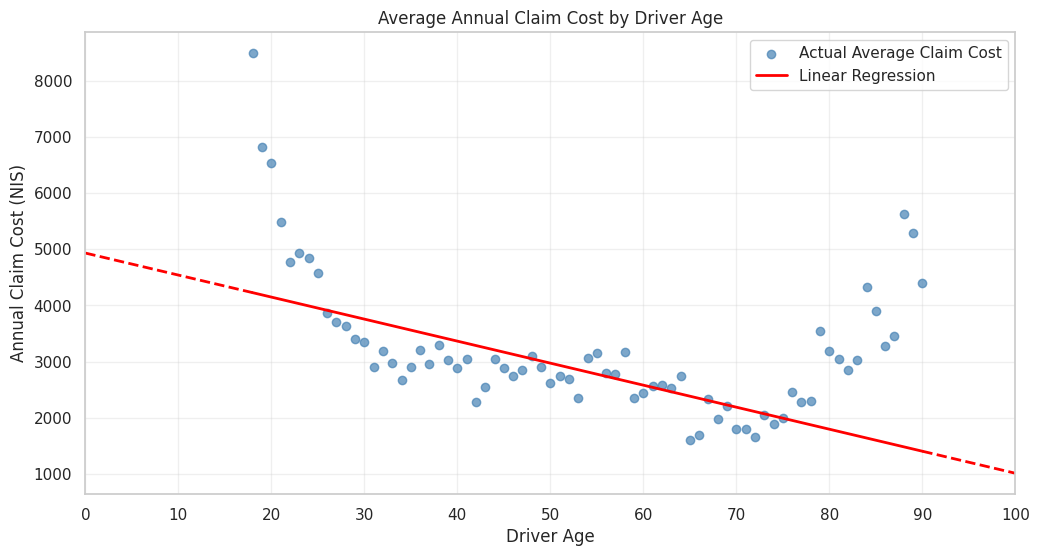

In [12]:

# יצירת טווח גילאים מ-0 עד 100
ages = pd.DataFrame({
    'driver_age': np.arange(0, 101)
})

# חיזוי עלות התביעות לכל גיל
age_predictions = age_model.predict(ages)

# חישוב עלות התביעות הממוצעת בפועל לכל גיל
age_means = age_data.groupby('driver_age')[
    'annual_claim_cost'
].mean().reset_index()

# טווח הגילאים הקיים בדאטה
min_age = int(X_age['driver_age'].min())
max_age = int(X_age['driver_age'].max())

# יצירת הגרף
plt.figure(figsize=(12, 6))

# הצגת ממוצע עלות התביעות בפועל בכל גיל
plt.scatter(
    age_means['driver_age'],
    age_means['annual_claim_cost'],
    color='steelblue',
    alpha=0.7,
    label='Actual Average Claim Cost'
)

# קו הרגרסיה בטווח הגילאים הקיים בדאטה
inside = (ages['driver_age'] >= min_age) & (
    ages['driver_age'] <= max_age
)

plt.plot(
    ages.loc[inside, 'driver_age'],
    age_predictions[inside],
    color='red',
    linewidth=2,
    label='Linear Regression'
)

# קו מקווקו עבור גילאים שמחוץ לטווח הנתונים
for mask in [
    ages['driver_age'] <= min_age,
    ages['driver_age'] >= max_age
]:
    plt.plot(
        ages.loc[mask, 'driver_age'],
        age_predictions[mask],
        color='red',
        linestyle='--',
        linewidth=2
    )

# עיצוב הגרף
plt.title('Average Annual Claim Cost by Driver Age')
plt.xlabel('Driver Age')
plt.ylabel('Annual Claim Cost (NIS)')
plt.xlim(0, 100)
plt.xticks(np.arange(0, 101, 10))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


<div dir="rtl" style="text-align: right;">

### **פרשנות תוצאות הרגרסיה הליניארית לפי גיל הנהג:**


<div dir="rtl" style="text-align: right;">


<p>
בנינו מודל רגרסיה ליניארית פשוטה במטרה לבחון
את הקשר בין גיל הנהג לבין עלות התביעות השנתית.
המודל מבוסס על המשתנה המסביר
<code>driver_age</code> בלבד.
</p>

**תוצאות המודל:**

<ul>
<li>Intercept: 4,933.59</li>
<li>Slope: -39.22</li>
<li>R²: 0.0074</li>
</ul>

<p>
מקדם הגיל שהתקבל הוא שלילי ועומד על
39.22- ש"ח. כלומר, לפי המודל הליניארי,
כל עלייה של שנה בגיל הנהג קשורה לירידה
ממוצעת של כ-39.22 ש"ח בעלות התביעות החזויה.
</p>

<p>
ערך ה-R² שהתקבל הוא 0.0074,
כלומר גיל הנהג לבדו מסביר כ-0.74%
מהשונות בעלויות התביעות.
מכאן שלמודל הליניארי הפשוט יכולת הסבר נמוכה מאוד.
</p>

**ניתוח הגרף:**

<p>
מהגרף ניתן לראות כי עלות התביעות הממוצעת
גבוהה יחסית בקרב נהגים צעירים,
יורדת בגילאי הביניים ועולה שוב
בקרב נהגים מבוגרים.
</p>

<p>
לעומת זאת, קו הרגרסיה מציג מגמת ירידה
קבועה לאורך כל טווח הגילים.
הדבר מעיד על כך שהקשר בין גיל הנהג
לעלות התביעות אינו ליניארי לחלוטין,
ולכן המודל אינו מצליח לתאר היטב
את השינויים בעלויות בכל קבוצות הגיל.
</p>

<p>
התחזיות עבור גילאים מחוץ לטווח שנצפה
בדאטה (18–90) הן אקסטרפולציה,
ולכן יש להתייחס אליהן בזהירות.
</p>

**מסקנה עסקית:**

<p>
גיל הנהג עשוי לספק מידע לגבי עלות
התביעות הצפויה, אך אינו מספיק בפני עצמו
לחיזוי מדויק.
</p>

<p>
לכן, לא מומלץ להסתמך על גיל הנהג בלבד
בקבלת החלטות ביטוחיות.
בהמשך נשלב משתנים נוספים ונבחן מודלים
שמסוגלים לזהות קשרים מורכבים יותר בנתונים.
</p>

</div>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**2.4 אסטרטגיה לפי גיל הנהג**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נבחן את עלות התביעות הממוצעת ואת שיעור הנהגים היקרים לפי עשורי גיל.

בהתאם להנחיות המטלה, נהג יקר מוגדר כנהג שעלות התביעות השנתית שלו גבוהה מ־10,000 ש"ח.

על בסיס הממצאים נציע אסטרטגיה עסקית מתאימה לקבוצות הגיל השונות.

</div>


<div dir="rtl" style="text-align: right;">

### **ניתוח עלויות תביעות לפי עשורי גיל:**

In [13]:

# יצירת טבלה לצורך ניתוח לפי עשורי גיל
age_analysis = df[
    ['driver_age', 'annual_claim_cost']
].dropna().copy()

# חלוקת הנהגים לעשורי גיל
age_analysis['age_decade'] = (
    age_analysis['driver_age'] // 10 * 10
).astype(int)

# סימון נהגים יקרים
age_analysis['is_expensive'] = (
    age_analysis['annual_claim_cost'] > 10000
)

# חישוב מדדים לכל עשור
age_summary = age_analysis.groupby('age_decade').agg(
    drivers_count=('annual_claim_cost', 'count'),
    mean_claim_cost=('annual_claim_cost', 'mean'),
    median_claim_cost=('annual_claim_cost', 'median'),
    std_claim_cost=('annual_claim_cost', 'std'),
    expensive_rate=('is_expensive', 'mean')
)

# המרת שיעור הנהגים היקרים לאחוזים
age_summary['expensive_rate'] *= 100

# עיגול התוצאות
age_summary = age_summary.round(2)

# הצגת הטבלה
display(age_summary)


,drivers_count,mean_claim_cost,median_claim_cost,std_claim_cost,expensive_rate
age_decade,,,,,
10,838,7643.64,2866.5,14931.62,20.29
20,6204,4459.16,0.0,9723.95,13.44
30,8187,3048.51,0.0,7313.40,9.25
40,9359,2828.56,0.0,6946.42,8.88
50,8534,2766.58,0.0,6911.63,8.12
60,6587,2295.99,0.0,5890.49,7.03
70,3892,2085.37,0.0,5683.55,6.78
80,1359,3503.39,0.0,8551.93,10.52
90,40,4404.20,0.0,9834.22,10.00


<div dir="rtl" style="text-align: right;">

### **הצגת עלות התביעות ושיעור הנהגים היקרים לפי קבוצות גיל:**

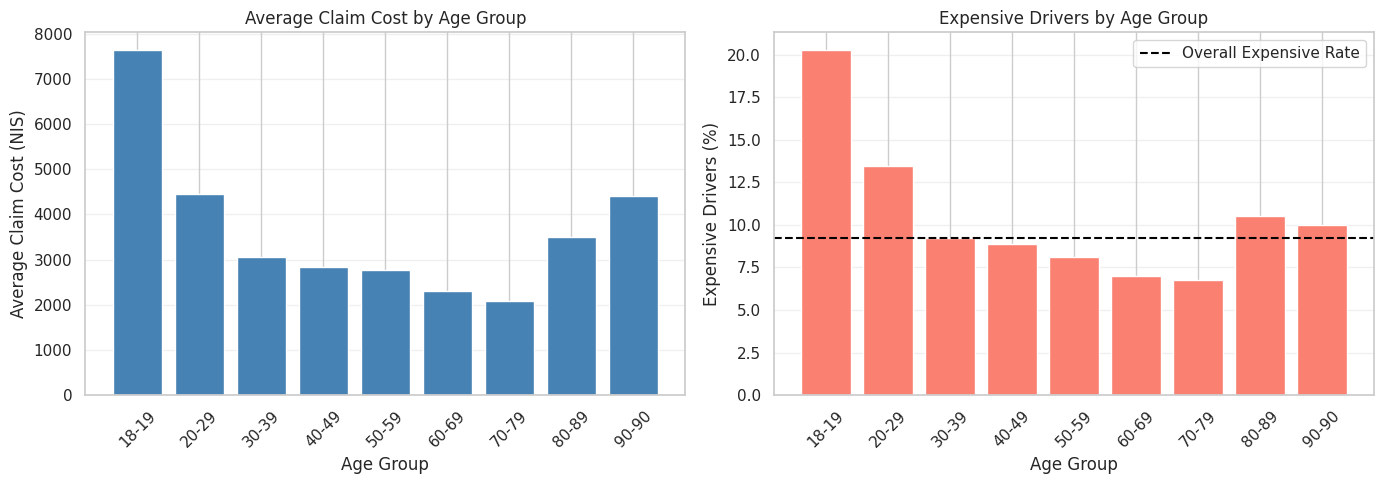

In [14]:

# יצירת תוויות גיל בהתאם לגילאים הקיימים בכל קבוצה
age_ranges = age_analysis.groupby('age_decade')['driver_age'].agg(
    ['min', 'max']
)

age_labels = [
    f"{int(row['min'])}-{int(row['max'])}"
    for _, row in age_ranges.iterrows()
]

# יצירת שני גרפים
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# גרף 1: עלות תביעות ממוצעת לפי קבוצת גיל
axes[0].bar(
    age_labels,
    age_summary['mean_claim_cost'],
    color='steelblue'
)

axes[0].set_title('Average Claim Cost by Age Group')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Average Claim Cost (NIS)')

# גרף 2: אחוז הנהגים היקרים לפי קבוצת גיל
axes[1].bar(
    age_labels,
    age_summary['expensive_rate'],
    color='salmon'
)

# קו המייצג את שיעור הנהגים היקרים בכלל הדאטה
overall_rate = (df['annual_claim_cost'] > 10000).mean() * 100

axes[1].axhline(
    y=overall_rate,
    color='black',
    linestyle='--',
    label='Overall Expensive Rate'
)

axes[1].set_title('Expensive Drivers by Age Group')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Expensive Drivers (%)')
axes[1].legend()

# עיצוב הגרפים
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">

### **ניתוח אסטרטגיה ביטוחית לפי קבוצות גיל והמלצות עסקיות:**


<div dir="rtl" style="text-align: right;">

<p>
בחנו את עלות התביעות הממוצעת ואת שיעור הנהגים היקרים
בקבוצות גיל שונות, במטרה לגבש המלצות עסקיות
לחברת הביטוח.
</p>

<p>
נהג יקר הוגדר כנהג שעלות התביעות השנתית שלו
גבוהה מ-10,000 ש"ח.
שיעור הנהגים היקרים בכלל הדאטה הוא 9.24%.
</p>

**ממצאים מרכזיים:**

<p>
מהגרפים עולה כי עלות התביעות הממוצעת גבוהה יחסית
בגילים הצעירים, יורדת בהדרגה בגילאי הביניים
ומגיעה לרמה נמוכה יחסית בגילאי 70-79.
לאחר מכן ניכרת עלייה מחודשת בגילים המבוגרים.
</p>

<p>
מגמה דומה נצפתה גם בשיעור הנהגים היקרים,
ולכן נראה שהקשר בין גיל הנהג לבין עלות התביעות
אינו ליניארי.
</p>

**אסטרטגיות מוצעות לפי עשורי גיל:**

<p>
<b>גילאי 20-29 - ניהול סיכון מוגבר:</b>
</p>

<p>
עלות התביעות הממוצעת בקבוצה היא 4,459.16 ש"ח,
ושיעור הנהגים היקרים הוא 13.44%,
גבוה מהממוצע הכללי.
לכן מומלץ להציע תוכניות לעידוד נהיגה בטוחה,
כגון הדרכות נהיגה והטבות על שימוש במערכות ניטור,
ולבחון גורמי סיכון נוספים לפני קבלת החלטה ביטוחית.
</p>

<p>
<b>גילאי 40-49 - שימור לקוחות וניהול סיכון רגיל:</b>
</p>

<p>
עלות התביעות הממוצעת היא 2,828.56 ש"ח,
ושיעור הנהגים היקרים הוא 8.88%,
מעט מתחת לממוצע הכללי.
ניתן לשקול הטבות לשימור לקוחות בעלי היסטוריית
נהיגה טובה, תוך התחשבות במאפייני הנהג והרכב.
</p>

<p>
<b>גילאי 70-79 - התאמת הצעות ללקוחות בסיכון נמוך יחסית:</b>
</p>

<p>
בקבוצה זו נמצאה עלות תביעות ממוצעת של
2,085.37 ש"ח ושיעור נהגים יקרים של 6.78%,
מהנמוכים בקבוצות שנבדקו.
ניתן לשקול תוכניות שימור והטבות לנהגים
בעלי מאפייני סיכון נמוכים, בלי להסתמך
על הגיל בלבד.
</p>

<p>
<b>גילאי 80-89 - בחינה מותאמת של מאפייני הסיכון:</b>
</p>

<p>
עלות התביעות הממוצעת עולה ל-3,503.39 ש"ח,
ושיעור הנהגים היקרים מגיע ל-10.52%.
מומלץ לבחון גורמי סיכון רלוונטיים נוספים,
ולהציע אמצעים לשיפור הבטיחות,
מבלי להסיק שכל נהג בקבוצה הוא נהג בסיכון גבוה.
</p>

**מגבלות הניתוח:**

<p>
הניתוח מבוסס על ממוצעים ושיעורים שנצפו בדאטה,
ולכן אינו מוכיח קשר סיבתי בין גיל הנהג
לבין עלות התביעות.
</p>

<p>
יש להתייחס בזהירות גם לקבוצות קטנות.
לדוגמה, קבוצת גיל 90 כוללת 40 נהגים בלבד,
ולכן הממוצע שלה עשוי להיות פחות יציב.
</p>

<p>
בנוסף, הנתונים סינתטיים ואינם בהכרח מייצגים
את אוכלוסיית הנהגים בעולם האמיתי.
</p>

**מסקנה עסקית:**

<p>
גיל הנהג מספק מידע מסוים לגבי עלות התביעות הצפויה,
אך רמת הסיכון משתנה גם בתוך כל קבוצת גיל.
לכן, מומלץ לשלב מאפיינים נוספים,
כגון ניסיון נהיגה, היסטוריית תביעות
ומאפייני הרכב, כדי לקבל הערכת סיכון מדויקת יותר.
</p>

<p>
המלצות אלו הן ראשוניות וצריכות להיבחן
בהמשך באמצעות מודל החיזוי וניתוח הוגנות,
לפני שימוש בהן בהחלטות ביטוחיות בפועל.
</p>

</div>


<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**3. דרישות טכניות**</span>


<div dir="rtl" style="text-align: right;">


## <span dir="rtl" style="display:block; text-align:right;">**3.1 פונקציית prepare_data - הכנת הנתונים**</span>

<div dir="rtl" style="text-align: right;">

בסעיף זה נבנה את הפונקציה `prepare_data(df)`, בהתאם לדרישות המטלה.

הפונקציה תבצע בחירת משתנים רלוונטיים, ניקוי נתונים, טיפול בערכים לא תקינים והנדסת פיצ'רים.

הפונקציה תהיה דטרמיניסטית ותוכל לפעול גם על נהג בודד וגם על קבוצת נהגים חדשים, ללא שימוש במשתנה המטרה.

</div>


<div dir="rtl" style="text-align: right;">

### **בניית הפונקציה prepare_data(df) - בחירת משתנים:**

In [15]:

# רשימת המשתנים המותרים לשימוש במודל
feature_columns = [
    # פרטי הנהג
    'driver_age',
    'gender',
    'marital_status',
    'license_years',
    'prior_claims_5y',
    'no_claims_years',
    'violations_3y',

    # מאפייני הרכב
    'vehicle_type',
    'vehicle_age',
    'engine_hp',
    'vehicle_value',
    'safety_features_count',
    'has_telematics',

    # מאפייני השימוש
    'usage_type',
    'annual_km_estimated',
    'pct_intercity',
    'pct_night_driving',
    'parking_type',

    # מאפיינים גאוגרפיים
    'country',
    'area_type',
    'region_density',
    'winter_severity'
]

# פונקציה להכנת הנתונים - גרסה ראשונית
def prepare_data(df):

    # יצירת עותק כדי לא לשנות את הדאטה המקורי
    data = df.copy()

    # בחירת המשתנים הרלוונטיים בלבד
    data = data.reindex(columns=feature_columns)

    return data

# בדיקת הפונקציה
X = prepare_data(df)

print("Original shape:", df.shape)
print("Prepared shape:", X.shape)

display(X.head())


Original shape: (45000, 30)
Prepared shape: (45000, 22)


,driver_age,gender,marital_status,license_years,prior_claims_5y,no_claims_years,violations_3y,vehicle_type,vehicle_age,engine_hp,vehicle_value,safety_features_count,has_telematics,usage_type,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,country,area_type,region_density,winter_severity
0,75,F,widowed,54,2.0,0,0,suv,11,182,51000,2,0,leisure,7500.0,5,15,lot,ES,suburban,855,1.3
1,76,M,married,45,0.0,12,0,sedan,3,94,56500,5,1,leisure,3000.0,25,10,street,GB,suburban,1225,2.7
2,60,M,single,42,0.0,8,0,small,11,90,19500,3,0,commute,12500.0,0,5,garage,IL,suburban,1651,1.9
3,55,M,divorced,34,1.0,2,0,sedan,6,151,37500,5,0,commute,10000.0,5,5,street,JP,urban,5441,7.7
4,69,M,widowed,51,4.0,1,1,sedan,2,142,86000,7,0,leisure,NaN,5,40,street,FR,urban,3231,5.9


<div dir="rtl" style="text-align: right;">

### **תיקון סוג הנתונים בעמודה vehicle_value:**

In [16]:

# עדכון הפונקציה להכנת הנתונים
def prepare_data(df):

    # יצירת עותק של הנתונים
    data = df.copy()

    # בחירת המשתנים הרלוונטיים בלבד
    data = data.reindex(columns=feature_columns)

    # הסרת פסיקים והמרת שווי הרכב למספר
    data['vehicle_value'] = pd.to_numeric(
        data['vehicle_value'].astype('string').str.replace(
            ',', '', regex=False
        ).str.strip(),
        errors='coerce'
    )

    return data


# בדיקת הפונקציה המעודכנת
X = prepare_data(df)

print("Prepared shape:", X.shape)
print("Vehicle value type:", X['vehicle_value'].dtype)
print("Missing vehicle values:", X['vehicle_value'].isnull().sum())

display(X[['vehicle_value']].head())


Prepared shape: (45000, 22)
Vehicle value type: Int64
Missing vehicle values: 0


,vehicle_value
0,51000
1,56500
2,19500
3,37500
4,86000


<div dir="rtl" style="text-align: right;">

### **ניקוי ערכים לא תקינים במשתנים קטגוריאליים ובינאריים:**

In [17]:

# עדכון הפונקציה להכנת הנתונים
def prepare_data(df):

    # יצירת עותק של הנתונים
    data = df.copy()

    # בחירת המשתנים הרלוונטיים בלבד
    data = data.reindex(columns=feature_columns)

    # המרת שווי הרכב למשתנה מספרי
    data['vehicle_value'] = pd.to_numeric(
        data['vehicle_value'].astype('string')
        .str.replace(',', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

    # איחוד צורות הכתיבה של מגדר
    data['gender'] = (
        data['gender']
        .astype('string')
        .str.strip()
        .str.lower()
        .map({
            'm': 'M',
            'male': 'M',
            'f': 'F',
            'female': 'F'
        })
    )

    # המרת משתנה מערכת הניטור למספרי
    data['has_telematics'] = pd.to_numeric(
        data['has_telematics'],
        errors='coerce'
    )

    # ערכים שאינם 0 או 1 ייחשבו לחסרים
    data['has_telematics'] = data[
        'has_telematics'
    ].where(
        data['has_telematics'].isin([0, 1])
    )

    return data


# בדיקת הפונקציה המעודכנת
X = prepare_data(df)

print("Prepared shape:", X.shape)

print("\nGender values:")
print(X['gender'].value_counts(dropna=False))

print("\nTelematics values:")
print(X['has_telematics'].value_counts(dropna=False))


Prepared shape: (45000, 22)

Gender values:
gender
M    24238
F    20762
Name: count, dtype: int64

Telematics values:
has_telematics
0.0    36367
1.0     7997
NaN      636
Name: count, dtype: int64


<div dir="rtl" style="text-align: right;">

### **זיהוי ערכים חריגים ולא הגיוניים (Data Validation):**

In [18]:

# רשימת המשתנים המספריים
numeric_columns = [
    'driver_age',
    'license_years',
    'prior_claims_5y',
    'no_claims_years',
    'violations_3y',
    'vehicle_age',
    'engine_hp',
    'vehicle_value',
    'safety_features_count',
    'has_telematics',
    'annual_km_estimated',
    'pct_intercity',
    'pct_night_driving',
    'region_density',
    'winter_severity'
]

# הצגת טווח הערכים בכל משתנה
numeric_summary = X[numeric_columns].agg(
    ['min', 'median', 'max']
).T

numeric_summary['missing_values'] = (
    X[numeric_columns].isnull().sum()
)

display(numeric_summary)

# בדיקת ערכים לא תקינים או חשודים
invalid_values = {
    'License years greater than driver age':
        (X['license_years'] > X['driver_age']).sum(),

    'Annual km equal to 999999':
        (X['annual_km_estimated'] == 999999).sum(),

    'Safety features outside 0-8':
        ((X['safety_features_count'] < 0) |
         (X['safety_features_count'] > 8)).sum(),

    'Intercity percentage outside 0-100':
        ((X['pct_intercity'] < 0) |
         (X['pct_intercity'] > 100)).sum(),

    'Night driving percentage outside 0-100':
        ((X['pct_night_driving'] < 0) |
         (X['pct_night_driving'] > 100)).sum(),

    'Winter severity outside 0-10':
        ((X['winter_severity'] < 0) |
         (X['winter_severity'] > 10)).sum()
}

display(pd.DataFrame(
    invalid_values.items(),
    columns=['Validation Check', 'Number of Records']
))


,min,median,max,missing_values
driver_age,18.0,47.0,90.0,0
license_years,0.0,28.0,95.0,0
prior_claims_5y,0.0,1.0,6.0,3142
no_claims_years,0.0,3.0,30.0,0
violations_3y,0.0,0.0,6.0,0
vehicle_age,0.0,6.0,25.0,0
engine_hp,12.0,137.0,650.0,0
vehicle_value,3000.0,44500.0,700000.0,0
safety_features_count,0.0,4.0,8.0,0
has_telematics,0.0,0.0,1.0,636


,Validation Check,Number of Records
0,License years greater than driver age,153
1,Annual km equal to 999999,1386
2,Safety features outside 0-8,0
3,Intercity percentage outside 0-100,0
4,Night driving percentage outside 0-100,0
5,Winter severity outside 0-10,0


<div dir="rtl" style="text-align: right;">

### **עדכון prepare_data וטיפול בערכים לא תקינים:**

In [19]:

# עדכון הפונקציה להכנת הנתונים
def prepare_data(df):

    # בחירת המשתנים הרלוונטיים ויצירת עותק
    data = df.reindex(columns=feature_columns).copy()

    # המרת שווי הרכב למספר
    data['vehicle_value'] = pd.to_numeric(
        data['vehicle_value'].astype('string')
        .str.replace(',', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

    # איחוד צורות הכתיבה של מגדר
    data['gender'] = (
        data['gender'].astype('string')
        .str.strip()
        .str.lower()
        .map({
            'm': 'M',
            'male': 'M',
            'f': 'F',
            'female': 'F'
        })
    )

    # המרת המשתנים הנדרשים למספרים
    columns_to_numeric = [
        'driver_age',
        'license_years',
        'has_telematics',
        'annual_km_estimated',
        'safety_features_count',
        'pct_intercity',
        'pct_night_driving',
        'winter_severity'
    ]

    for col in columns_to_numeric:
        data[col] = pd.to_numeric(
            data[col], errors='coerce'
        )

    # תיקון ערכים לא תקינים במערכת ניטור
    data['has_telematics'] = data[
        'has_telematics'
    ].where(
        data['has_telematics'].isin([0, 1])
    )

    # תיקון שנות רישיון לא הגיוניות
    data['license_years'] = data[
        'license_years'
    ].where(
        (data['license_years'] >= 0) &
        (data['license_years'] <= data['driver_age'])
    )

    # טיפול בקילומטראז' לא תקין או חשוד
    data['annual_km_estimated'] = data[
        'annual_km_estimated'
    ].where(
        (data['annual_km_estimated'] >= 0) &
        (data['annual_km_estimated'] != 999999)
    )

    # בדיקת טווחים לפי מילון השדות
    valid_ranges = {
        'safety_features_count': (0, 8),
        'pct_intercity': (0, 100),
        'pct_night_driving': (0, 100),
        'winter_severity': (0, 10)
    }

    for col, (min_val, max_val) in valid_ranges.items():
        data[col] = data[col].where(
            data[col].between(min_val, max_val)
        )

    return data


# הפעלת הפונקציה על כל הדאטה
X = prepare_data(df)

print("Prepared shape:", X.shape)

# בדיקת הערכים החסרים לאחר הניקוי
print("\nMissing values after cleaning:")
print(X.isnull().sum().sort_values(ascending=False).head(10))


# בדיקה על נהג בודד ללא משתנה המטרה
single_driver = df.drop(
    columns=['annual_claim_cost']
).iloc[[0]].copy()

# הדמיית ערכים חדשים שלא הופיעו באימון
single_driver['gender'] = 'unknown'
single_driver['country'] = 'XX'

X_single = prepare_data(single_driver)

print("\nSingle driver shape:", X_single.shape)

# וידוא שהמבנה זהה לנתוני האימון
assert X_single.columns.tolist() == X.columns.tolist()
assert X_single.shape[0] == 1
assert 'annual_claim_cost' not in X_single.columns

print("Single driver test passed!")
display(X_single)


Prepared shape: (45000, 22)

Missing values after cleaning:
annual_km_estimated    5697
prior_claims_5y        3142
has_telematics          636
license_years           153
gender                    0
driver_age                0
no_claims_years           0
marital_status            0
vehicle_age               0
violations_3y             0
dtype: int64

Single driver shape: (1, 22)
Single driver test passed!


,driver_age,gender,marital_status,license_years,prior_claims_5y,no_claims_years,violations_3y,vehicle_type,vehicle_age,engine_hp,vehicle_value,safety_features_count,has_telematics,usage_type,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,country,area_type,region_density,winter_severity
0,75,NaN,widowed,54,2.0,0,0,suv,11,182,51000,2,0,leisure,7500.0,5,15,lot,XX,suburban,855,1.3


<div dir="rtl" style="text-align: right;">

### **תכנון הנדסת פיצ'רים (Feature Engineering):**


<div dir="rtl" style="text-align: right;">

<p>
מטרת הנדסת הפיצ'רים היא ליצור משתנים חדשים
מתוך המידע הקיים, במטרה לאפשר למודלים
לזהות קשרים נוספים בין מאפייני הנהג והרכב
לבין עלות התביעות השנתית.
</p>

<p>
ניצור שישה פיצ'רים חדשים המבוססים על
משתנים הידועים לפני תחילת הפוליסה.
</p>

**הפיצ'רים שנבחרו:**

<ol>

<li>
<b>age_squared - גיל הנהג בריבוע</b>
<p>
נוסחה: driver_age ** 2
</p>
<p>
מוטיבציה: בניתוח הראשוני ראינו שהקשר
בין גיל הנהג לעלות התביעות אינו ליניארי.
הוספת גיל בריבוע עשויה לאפשר למודל הליניארי
לייצג קשר שאינו קו ישר.
</p>
</li>

<li>
<b>license_start_age - גיל קבלת הרישיון</b>
<p>
נוסחה: driver_age - license_years
</p>
<p>
מוטיבציה: הפיצ'ר מתאר את הגיל המשוער
שבו הנהג קיבל את רישיון הנהיגה.
ייתכן שהוא מכיל מידע נוסף על ניסיון הנהיגה,
מעבר לגיל הנוכחי של הנהג.
</p>
</li>

<li>
<b>estimated_night_km - קילומטרים בנהיגת לילה</b>
<p>
נוסחה:
annual_km_estimated * pct_night_driving / 100
</p>
<p>
מוטיבציה: שילוב של היקף הנסיעה השנתי
עם שיעור הנהיגה בלילה.
הפיצ'ר עשוי לספק מדד לחשיפה לנהיגת לילה,
ולא רק לאחוז הנסיעות המתבצעות בלילה.
</p>
</li>

<li>
<b>estimated_intercity_km - קילומטרים בנסיעה בין-עירונית</b>
<p>
נוסחה:
annual_km_estimated * pct_intercity / 100
</p>
<p>
מוטיבציה: הערכת היקף הנסיעות הבין-עירוניות
בשנה, שעשוי לשקף דפוסי נהיגה שונים.
</p>
</li>

<li>
<b>vehicle_value_per_hp - שווי הרכב ביחס לעוצמת המנוע</b>
<p>
נוסחה: vehicle_value / engine_hp
</p>
<p>
מוטיבציה: בחינת הקשר בין שווי הרכב
לעוצמת המנוע. ייתכן ששילוב המאפיינים
יסייע להבחין בין סוגי רכבים בעלי
מאפייני סיכון שונים.
</p>
<p>
אם עוצמת המנוע חסרה או אינה חיובית,
לא נבצע חלוקה ונשאיר ערך חסר.
</p>
</li>

<li>
<b>vehicle_age_km_interaction - אינטראקציה בין גיל הרכב לקילומטראז'</b>
<p>
נוסחה: vehicle_age * annual_km_estimated
</p>
<p>
מוטיבציה: שילוב בין גיל הרכב לבין היקף
השימוש בו. ייתכן שרכב ישן שנוסע קילומטרים
רבים מציג מאפייני סיכון שונים מרכב
באותו גיל שנוסע מעט.
</p>
</li>

</ol>

**מניעת Data Leakage:**

<p>
כל הפיצ'רים נבנים ממשתנים שאמורים להיות
ידועים לפני תחילת שנת הביטוח.
החישובים דטרמיניסטיים ואינם משתמשים
במשתנה המטרה או בנתוני נהגים אחרים.
</p>

<p>
אם אחד מערכי המקור חסר, הפיצ'ר המחושב
יכול להישאר חסר. השלמת הערכים תתבצע
בהמשך בתוך ה-Pipeline.
</p>

**סיכום:**

<p>
הפיצ'רים החדשים נועדו להוסיף מידע על
ניסיון הנהיגה, דפוסי השימוש ברכב
והקשר בין מאפייני הרכב.
</p>

<p>
בהמשך נבחן האם הפיצ'רים תורמים
לביצועי המודלים באמצעות Cross Validation.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **הוספת ששת הפיצ'רים לפונקציית prepare_data:**

In [20]:

# עדכון הפונקציה להכנת הנתונים
def prepare_data(df):

    # בחירת המשתנים הרלוונטיים ויצירת עותק
    data = df.reindex(columns=feature_columns).copy()

    # המרת שווי הרכב למספר
    data['vehicle_value'] = pd.to_numeric(
        data['vehicle_value'].astype('string')
        .str.replace(',', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

    # המרת המשתנים המספריים
    for col in numeric_columns:
        if col != 'vehicle_value':
            data[col] = pd.to_numeric(
                data[col], errors='coerce'
            )

    # איחוד צורות כתיבה של מגדר
    data['gender'] = (
        data['gender'].astype('string')
        .str.strip()
        .str.lower()
        .map({
            'm': 'M',
            'male': 'M',
            'f': 'F',
            'female': 'F'
        })
        .astype(object)
    )

    # המרת ערכים חסרים לפורמט מתאים ל - sklearn
    data['gender'] = data['gender'].where(
        data['gender'].notna(), np.nan
    )

    # תיקון ערכים לא תקינים במערכת ניטור
    data['has_telematics'] = data[
        'has_telematics'
    ].where(
        data['has_telematics'].isin([0, 1])
    )

    # תיקון שנות רישיון לא הגיוניות
    data['license_years'] = data[
        'license_years'
    ].where(
        (data['license_years'] >= 0) &
        (data['license_years'] <= data['driver_age'])
    )

    # טיפול בקילומטראז' לא תקין או חשוד
    data['annual_km_estimated'] = data[
        'annual_km_estimated'
    ].where(
        (data['annual_km_estimated'] >= 0) &
        (data['annual_km_estimated'] != 999999)
    )

    # בדיקת טווחים לפי מילון השדות
    valid_ranges = {
        'safety_features_count': (0, 8),
        'pct_intercity': (0, 100),
        'pct_night_driving': (0, 100),
        'winter_severity': (0, 10)
    }

    for col, (min_val, max_val) in valid_ranges.items():
        data[col] = data[col].where(
            data[col].between(min_val, max_val)
        )

    # המרה לפורמט מספרי אחיד
    for col in numeric_columns:
        data[col] = data[col].astype(float)

    # ---------------------------------
    # Feature Engineering
    # ---------------------------------

    # פיצ'ר 1: גיל הנהג בריבוע
    data['age_squared'] = data['driver_age'] ** 2

    # פיצ'ר 2: גיל משוער בעת קבלת הרישיון
    data['license_start_age'] = (
        data['driver_age'] - data['license_years']
    )

    # פיצ'ר 3: קילומטרים משוערים בנהיגת לילה
    data['estimated_night_km'] = (
        data['annual_km_estimated'] *
        data['pct_night_driving'] / 100
    )

    # פיצ'ר 4: קילומטרים משוערים בנסיעה בין-עירונית
    data['estimated_intercity_km'] = (
        data['annual_km_estimated'] *
        data['pct_intercity'] / 100
    )

    # פיצ'ר 5: יחס שווי הרכב לעוצמת המנוע
    safe_hp = data['engine_hp'].where(
        data['engine_hp'] > 0
    )

    data['vehicle_value_per_hp'] = (
        data['vehicle_value'] / safe_hp
    )

    # פיצ'ר 6: אינטראקציה בין גיל הרכב לקילומטראז'
    data['vehicle_age_km_interaction'] = (
        data['vehicle_age'] *
        data['annual_km_estimated']
    )

    return data


# הפעלת הפונקציה על כל הנתונים
X = prepare_data(df)

print("Original shape:", df.shape)
print("Prepared shape:", X.shape)

# הצגת הפיצ'רים החדשים
new_features = [
    'age_squared',
    'license_start_age',
    'estimated_night_km',
    'estimated_intercity_km',
    'vehicle_value_per_hp',
    'vehicle_age_km_interaction'
]

display(X[new_features].head())

#בדיקה נוספת של הפונקציה

# הכנת נתוני בדיקה ללא משתנה המטרה
test_input = df.drop(columns=['annual_claim_cost'])

# בדיקה על נהג בודד
single_driver = test_input.iloc[[0]].copy()

# הדמיית ערכים חדשים או לא תקינים
single_driver['gender'] = 'unknown'
single_driver['country'] = 'XX'
single_driver['engine_hp'] = 0
single_driver['annual_km_estimated'] = 999999

X_single = prepare_data(single_driver)

# בדיקה על 100 נהגים
X_batch = prepare_data(test_input.iloc[:100])

# וידוא מבנה זהה
assert X_single.shape == (1, 28)
assert X_batch.shape == (100, 28)
assert X_single.columns.tolist() == X.columns.tolist()
assert X_batch.columns.tolist() == X.columns.tolist()

# בדיקת טיפול בחלוקה באפס
assert pd.isna(
    X_single['vehicle_value_per_hp'].iloc[0]
)

# בדיקה שמשתנה המטרה אינו מופיע
assert 'annual_claim_cost' not in X_single.columns

print("All tests passed!")


Original shape: (45000, 30)
Prepared shape: (45000, 28)


,age_squared,license_start_age,estimated_night_km,estimated_intercity_km,vehicle_value_per_hp,vehicle_age_km_interaction
0,5625.0,21.0,1125.0,375.0,280.219780,82500.0
1,5776.0,31.0,300.0,750.0,601.063830,9000.0
2,3600.0,18.0,625.0,0.0,216.666667,137500.0
3,3025.0,21.0,500.0,500.0,248.344371,60000.0
4,4761.0,18.0,NaN,NaN,605.633803,NaN


All tests passed!


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**3.2 בניית המודלים - Elastic Net ו-Random Forest**</span>




<div dir="rtl" style="text-align: right;">

בסעיף זה נבנה את תהליך העיבוד המקדים באמצעות Pipeline ו-ColumnTransformer, ולאחר מכן את מודלי Elastic Net ו-Random Forest.

השלמת ערכים חסרים, תקנון וקידוד משתנים יתבצעו בתוך ה-Pipeline כדי למנוע דליפת מידע במהלך האימון וההערכה.

</div>


<div dir="rtl" style="text-align: right;">

### **בניית Pipeline לעיבוד מקדים של הנתונים:**

In [21]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# הגדרת המשתנים המספריים
numeric_features = numeric_columns + new_features

# הגדרת המשתנים הקטגוריאליים
categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

# Pipeline למשתנים מספריים
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline למשתנים קטגוריאליים
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore'
    ))
])

# שילוב שני תהליכי העיבוד
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# בדיקת מספר המשתנים
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", X.shape[1])


Numeric features: 21
Categorical features: 7
Total features: 28


<div dir="rtl" style="text-align: right;">

### **בניית מודל Elastic Net באמצעות Pipeline:**

In [22]:

from sklearn.linear_model import ElasticNet

# הגדרת משתנה המטרה
y = df['annual_claim_cost']

# יצירת מודל Elastic Net
elastic_net = ElasticNet(
    random_state=42,
    max_iter=20000
)

# שילוב העיבוד המקדים והמודל ב- Pipeline
elastic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', elastic_net)
])

# בדיקת מבנה הנתונים וה- Pipeline
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nElastic Net Pipeline:")
print(elastic_pipeline)


X shape: (45000, 28)
y shape: (45000,)

Elastic Net Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['driver_age',
                                                   'license_years',
                                                   'prior_claims_5y',
                                                   'no_claims_years',
                                                   'violations_3y',
                                                   'vehicle_age', 'engine_hp',
                                                   'vehicle_value',
               

<div dir="rtl" style="text-align: right;">

### **כוונון פרמטרים ל־Elastic Net באמצעות GridSearchCV:**

In [23]:

from sklearn.model_selection import GridSearchCV, KFold

#  הגדרת 10- Fold Cross Validation
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# טווח הערכים שנבדוק עבור כל פרמטר
param_grid = {
    'model__alpha': [0.1, 1, 10, 100],
    'model__l1_ratio': [0.2, 0.5, 0.8]
}

# הגדרת תהליך חיפוש הפרמטרים
grid_search = GridSearchCV(
    estimator=elastic_pipeline,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# הצגת מספר השילובים והאימונים
n_combinations = (
    len(param_grid['model__alpha']) *
    len(param_grid['model__l1_ratio'])
)

print("Parameter combinations:", n_combinations)
print("CV folds:", cv.get_n_splits())
print("Total fits:", n_combinations * cv.get_n_splits())



Parameter combinations: 12
CV folds: 10
Total fits: 120


<div dir="rtl" style="text-align: right;">

### **הרצת GridSearchCV ובחירת הפרמטרים הטובים ביותר:**

In [24]:

# הרצת GridSearchCV למציאת הפרמטרים הטובים ביותר
grid_search.fit(X, y)

# הצגת הפרמטרים שנבחרו
print("Best Parameters:")
print(grid_search.best_params_)

# הצגת שגיאת ה- RMSE הטובה ביותר
best_rmse = -grid_search.best_score_

print("\nBest CV RMSE:", round(best_rmse, 2))

# יצירת טבלה עם תוצאות כל שילובי הפרמטרים
results = pd.DataFrame(grid_search.cv_results_)

results_summary = results[[
    'param_model__alpha',
    'param_model__l1_ratio',
    'mean_test_score',
    'std_test_score'
]].copy()

# המרת הציונים לערכי RMSE חיוביים
results_summary['mean_test_score'] *= -1

# שינוי שמות העמודות
results_summary.columns = [
    'Alpha',
    'L1 Ratio',
    'Mean RMSE',
    'Std RMSE'
]

# מיון התוצאות לפי RMSE מהנמוך לגבוה
results_summary = results_summary.sort_values(
    by='Mean RMSE'
)

display(results_summary.round(2))


Fitting 10 folds for each of 12 candidates, totalling 120 fits
Best Parameters:
{'model__alpha': 0.1, 'model__l1_ratio': 0.8}

Best CV RMSE: 6759.28


,Alpha,L1 Ratio,Mean RMSE,Std RMSE
2,0.1,0.8,6759.28,388.92
1,0.1,0.5,6777.96,392.05
0,0.1,0.2,6790.68,394.10
5,1.0,0.8,6824.15,399.69
4,1.0,0.5,6874.86,408.53
3,1.0,0.2,6913.68,414.75
8,10.0,0.8,7034.18,429.06
7,10.0,0.5,7198.61,441.23
6,10.0,0.2,7282.50,445.56
11,100.0,0.8,7419.57,450.85


<div dir="rtl" style="text-align: right;">

### **ניתוח תוצאות GridSearchCV כוונון הפרמטרים של Elastic Net:**


<div dir="rtl" style="text-align: right;">


<p>
ביצענו כוונון פרמטרים באמצעות GridSearchCV
עם 10-Fold Cross Validation.
נבדקו 12 שילובים של alpha ו-l1_ratio,
כאשר המדד לבחירת השילוב הטוב ביותר היה RMSE.
</p>

**תוצאות החיפוש:**

<ul>
<li>alpha הטוב ביותר: 0.1</li>
<li>l1_ratio הטוב ביותר: 0.8</li>
<li>RMSE ממוצע: 6,759.28 ש"ח</li>
<li>סטיית תקן של RMSE בין ה- Folds : 388.92 ש"ח</li>
</ul>

**פרשנות הפרמטרים:**

<p>
הערך alpha=0.1 מייצג את עוצמת הרגולריזציה
הנמוכה ביותר מבין הערכים שנבדקו.
הדבר עשוי להצביע על כך שרגולריזציה חזקה יותר
פוגעת ביכולת החיזוי של המודל.
</p>

<p>
הערך l1_ratio=0.8 מעיד על שילוב רגולריזציה
שבו לרכיב L1 משקל גבוה יחסית לרכיב L2.
רכיב L1 עשוי לגרום לאיפוס מקדמים מסוימים,
אך נדרשת בדיקת המקדמים כדי לדעת
אילו משתנים אכן אופסו.
</p>

**השוואה בין השילובים:**

<p>
השילוב הטוב ביותר השיג RMSE של 6,759.28 ש"ח,
לעומת 6,777.96 ש"ח עבור השילוב
alpha=0.1 ו-l1_ratio=0.5.
</p>

<p>
ההפרש בין שני השילובים קטן יחסית,
ולכן לא ניתן לקבוע על סמך התוצאות הללו
שקיים הבדל משמעותי בביצועיהם.
</p>

**מסקנה והמשך העבודה:**

<p>
מכיוון שהפרמטרים הטובים ביותר נמצאו
בקצות טווח החיפוש, נרחיב את טווח הערכים
ונבדוק האם ניתן לשפר את ביצועי המודל.
</p>

<p>
חשוב לציין שתוצאות GridSearchCV משמשות
בשלב זה לבחירת פרמטרים בלבד.
בהמשך נבצע הערכה נפרדת באמצעות
Cross Validation, ונדווח על RMSE, MAE ו-R²
כולל ממוצע וסטיית תקן.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **הרחבת חיפוש הפרמטרים של Elastic Net:**

In [25]:

# הגדרת טווח פרמטרים ממוקד יותר
refined_param_grid = {
    'model__alpha': [0.01, 0.03, 0.1],
    'model__l1_ratio': [0.8, 0.9, 0.95]
}

# יצירת GridSearchCV נוסף
refined_grid_search = GridSearchCV(
    estimator=elastic_pipeline,
    param_grid=refined_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=2,
    refit=True,
    verbose=1
)

# הרצת החיפוש
refined_grid_search.fit(X, y)

# הצגת הפרמטרים הטובים ביותר
print("Best Parameters:")
print(refined_grid_search.best_params_)

# חישוב RMSE
refined_rmse = -refined_grid_search.best_score_

print("\nRefined CV RMSE:", round(refined_rmse, 2))

# השוואה לחיפוש הראשון
print("Original CV RMSE:", round(best_rmse, 2))
print("Improvement (NIS):", round(best_rmse - refined_rmse, 2))

# טבלת תוצאות החיפוש
refined_results = pd.DataFrame({
    'Alpha': refined_grid_search.cv_results_['param_model__alpha'],
    'L1 Ratio': refined_grid_search.cv_results_['param_model__l1_ratio'],
    'Mean RMSE': -refined_grid_search.cv_results_['mean_test_score'],
    'Std RMSE': refined_grid_search.cv_results_['std_test_score']
})

refined_results = refined_results.sort_values(
    by='Mean RMSE'
)

display(refined_results.round(2))


Fitting 10 folds for each of 9 candidates, totalling 90 fits
Best Parameters:
{'model__alpha': 0.01, 'model__l1_ratio': 0.95}

Refined CV RMSE: 6742.38
Original CV RMSE: 6759.28
Improvement (NIS): 16.89


,Alpha,L1 Ratio,Mean RMSE,Std RMSE
2,0.01,0.95,6742.38,383.51
1,0.01,0.90,6742.55,383.82
5,0.03,0.95,6742.81,384.13
0,0.01,0.80,6743.12,384.39
4,0.03,0.90,6743.86,384.87
8,0.10,0.95,6745.63,385.69
3,0.03,0.80,6746.53,386.00
7,0.10,0.90,6750.41,387.10
6,0.10,0.80,6759.28,388.92


<div dir="rtl" style="text-align: right;">

### **ניתוח תוצאות כוונון הפרמטרים המורחב:**


<div dir="rtl" style="text-align: right;">

<h3>סיכום כוונון הפרמטרים של Elastic Net:</h3>

<p>
לאחר החיפוש הראשוני, ביצענו חיפוש ממוקד נוסף
באמצעות GridSearchCV עם 10-Fold Cross Validation,
כדי לבדוק האם ניתן לשפר את ביצועי המודל.
</p>

**תוצאות החיפוש המורחב:**

<ul>
<li>alpha הטוב ביותר: 0.01</li>
<li>l1_ratio הטוב ביותר: 0.95</li>
<li>RMSE ממוצע: 6,742.38 ש"ח</li>
<li>סטיית תקן בין ה-Folds: 383.51 ש"ח</li>
</ul>

**השוואה לחיפוש הראשון:**

<p>
בחיפוש הראשון התקבל RMSE של 6,759.28 ש"ח,
לעומת 6,742.38 ש"ח בחיפוש המורחב.
מדובר בשיפור של כ-16.90 ש"ח,
המהווה כ-0.25% משגיאת החיזוי הקודמת.
</p>

<p>
למרות שנמצא שיפור, הוא קטן יחסית.
בנוסף, תוצאות השילובים המובילים בחיפוש
המורחב קרובות מאוד זו לזו.
לכן אין עדיין עדות להבדל משמעותי
ביכולת החיזוי של שילובים אלו.
</p>

**פרשנות הפרמטרים:**

<p>
הערך alpha=0.01 מצביע על רגולריזציה
חלשה יחסית מבין האפשרויות שנבדקו.
</p>

<p>
הערך l1_ratio=0.95 מצביע על משקל גבוה
מאוד לרכיב L1 לעומת רכיב L2.
רגולריזציה מסוג L1 עשויה לאפס
מקדמים של חלק מהפיצ'רים.
</p>

**מסקנה:**

<p>
הרחבת החיפוש אפשרה למצוא שילוב פרמטרים
עם RMSE נמוך יותר, אך השיפור קטן.
לכן אין הצדקה להסיק שהשילוב החדש
עדיף באופן משמעותי על האחרים.
</p>

<p>
נשתמש בתוצאות החיפוש לצורך תכנון
שלב הערכת המודל.
הביצועים הסופיים ייבדקו באמצעות
Cross Validation חיצוני,
שבו בחירת הפרמטרים מתבצעת
על נתוני האימון בלבד.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **בניית מודל Random Forest באמצעות Pipeline:**

In [26]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

# יצירת מודל Random Forest
random_forest = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=2
)

# שילוב העיבוד המקדים והמודל ב-Pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', clone(preprocessor)),
    ('model', random_forest)
])

# הצגת מבנה הנתונים וה-Pipeline
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nRandom Forest Pipeline:")
print(rf_pipeline)


X shape: (45000, 28)
y shape: (45000,)

Random Forest Pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['driver_age',
                                                   'license_years',
                                                   'prior_claims_5y',
                                                   'no_claims_years',
                                                   'violations_3y',
                                                   'vehicle_age', 'engine_hp',
                                                   'vehicle_value',
             

In [27]:

# בדיקת תקינות לפני הערכת המודלים

# בדיקת מבנה הנתונים
assert X.shape[1] == 28
assert len(feature_columns) == 22
assert len(new_features) == 6

# בדיקת קיום ששת הפיצ'רים החדשים
assert all(col in X.columns for col in new_features)

# בדיקת התאמה בין הפיצ'רים לעיבוד המקדים
assert set(numeric_features).isdisjoint(
    set(categorical_features)
)

assert (
    set(numeric_features) |
    set(categorical_features)
) == set(X.columns)

# בדיקה שמשתנה המטרה לא נמצא בקלט
assert 'annual_claim_cost' not in X.columns

# בדיקת הגדרת שני המודלים
assert isinstance(
    elastic_pipeline.named_steps['model'],
    ElasticNet
)

assert isinstance(
    rf_pipeline.named_steps['model'],
    RandomForestRegressor
)

# בדיקת מספר התצפיות
assert len(X) == len(y) == 45000

print("Data preparation: PASSED")
print("Feature engineering: PASSED")
print("Preprocessing: PASSED")
print("Elastic Net Pipeline: PASSED")
print("Random Forest Pipeline: PASSED")
print("\nPre-CV checks: ALL PASSED")


Data preparation: PASSED
Feature engineering: PASSED
Preprocessing: PASSED
Elastic Net Pipeline: PASSED
Random Forest Pipeline: PASSED

Pre-CV checks: ALL PASSED


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**3.3 הערכת המודלים - 10-Fold Cross Validation**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נעריך את ביצועי המודלים Elastic Net ו-Random Forest באמצעות 10-Fold Cross Validation.

נחשב עבור כל מודל שלושה מדדים:

- **RMSE** - שורש ממוצע השגיאות הריבועיות.
- **MAE** - ממוצע השגיאות המוחלטות.
- **R²** - שיעור השונות המוסברת על ידי המודל.

נדווח על הממוצע וסטיית התקן של כל מדד לאורך עשרת ה-Folds, ונשווה בין המודלים.

</div>


<div dir="rtl" style="text-align: right;">

### **הערכת Elastic Net באמצעות Nested Cross Validation:**

In [31]:

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# הגדרת Cross Validation חיצוני ופנימי
outer_cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

inner_cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# טווח הפרמטרים שייבדק בכל Fold פנימי
nested_param_grid = {
    'model__alpha': [0.01, 0.1, 1, 10],
    'model__l1_ratio': [0.2, 0.8, 0.95]
}

# שמירת תוצאות ותחזיות
elastic_cv_results = []
elastic_oof_pred = np.full(len(y), np.nan)

# מעבר על עשרת ה- Folds החיצוניים
for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # חיפוש פרמטרים על נתוני האימון בלבד
    search = GridSearchCV(
        estimator=elastic_pipeline,
        param_grid=nested_param_grid,
        scoring='neg_root_mean_squared_error',
        cv=inner_cv,
        n_jobs=2,
        refit=True
    )

    search.fit(X_train, y_train)

    # תחזיות על ה- Fold החיצוני
    y_pred = search.predict(X_test)

    # שמירת התחזיות לניתוח שגיאות והוגנות בהמשך
    elastic_oof_pred[test_idx] = y_pred

    # חישוב מדדי הביצוע
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    elastic_cv_results.append({
        'Fold': fold,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2,
        'Best Alpha': search.best_params_['model__alpha'],
        'Best L1 Ratio': search.best_params_['model__l1_ratio']
    })

    print(f"Fold {fold}/10 completed | RMSE: {rmse:.2f}")

# טבלת תוצאות
elastic_cv_df = pd.DataFrame(elastic_cv_results)

display(elastic_cv_df.round(2))

# חישוב ממוצע וסטיית תקן לכל מדד
elastic_summary = elastic_cv_df[
    ['RMSE', 'MAE', 'R2']
].agg(['mean', 'std'])

print("\nElastic Net - CV Summary:")
display(elastic_summary.round(2))

# וידוא שכל הנהגים קיבלו תחזית
assert not np.isnan(elastic_oof_pred).any()

print("All out-of-fold predictions saved successfully!")


Fold 1/10 completed | RMSE: 7269.03
Fold 2/10 completed | RMSE: 6754.69
Fold 3/10 completed | RMSE: 6972.12
Fold 4/10 completed | RMSE: 6210.15
Fold 5/10 completed | RMSE: 6996.57
Fold 6/10 completed | RMSE: 6359.78
Fold 7/10 completed | RMSE: 6321.66
Fold 8/10 completed | RMSE: 7299.20
Fold 9/10 completed | RMSE: 6874.64
Fold 10/10 completed | RMSE: 6365.99


,Fold,RMSE,MAE,R2,Best Alpha,Best L1 Ratio
0,1,7269.03,3907.70,0.22,0.01,0.95
1,2,6754.69,3826.73,0.18,0.01,0.95
2,3,6972.12,3767.30,0.18,0.01,0.95
3,4,6210.15,3672.74,0.18,0.01,0.95
4,5,6996.57,3721.60,0.21,0.01,0.95
5,6,6359.78,3787.90,0.19,0.01,0.95
6,7,6321.66,3698.87,0.21,0.01,0.95
7,8,7299.20,3821.00,0.20,0.01,0.95
8,9,6874.64,3783.23,0.22,0.01,0.95
9,10,6365.99,3716.45,0.20,0.01,0.95



Elastic Net - CV Summary:


,RMSE,MAE,R2
mean,6742.38,3770.35,0.20
std,404.25,70.72,0.02


All out-of-fold predictions saved successfully!


<div dir="rtl" style="text-align: right;">

### **ניתוח ביצועי Elastic Net:**


<div dir="rtl" style="text-align: right;">

<p>
הערכנו את ביצועי מודל Elastic Net באמצעות
Nested Cross Validation, עם 10 Folds חיצוניים
להערכת הביצועים ו-3 Folds פנימיים
לכוונון הפרמטרים.
</p>

<p>
בכל Fold בוצעו העיבוד המקדים, בחירת הפרמטרים
ואימון המודל על נתוני האימון בלבד.
התחזיות נבדקו על נתוני הוולידציה החיצוניים.
</p>

**תוצאות המודל:**

<ul>
<li>
<b>RMSE:</b> ממוצע 6,742.38 ש"ח,
סטיית תקן 404.25 ש"ח.
</li>

<li>
<b>MAE:</b> ממוצע 3,770.35 ש"ח,
סטיית תקן 70.72 ש"ח.
</li>

<li>
<b>R²:</b> ממוצע 0.20,
סטיית תקן 0.02.
</li>
</ul>

**פרשנות מדדי הביצוע:**

<p>
מדד ה-RMSE מעניק משקל גבוה יותר לשגיאות
גדולות. הערך שהתקבל מצביע על כך
שהמודל עדיין מתקשה בחיזוי מדויק של
עלויות תביעות, במיוחד כאשר קיימות
תביעות בעלות גבוהה.
</p>

<p>
מדד ה-MAE מצביע על שגיאה מוחלטת ממוצעת
של כ-3,770 ש"ח לתחזית.
</p>

<p>
ערך ה-R² הממוצע הוא 0.20,
כלומר המודל מסביר בממוצע כ-20%
מהשונות בעלויות התביעות
בנתוני הוולידציה ביחס לחיזוי קבוע
של ממוצע נתוני אותו Fold.
</p>

**יציבות המודל בין ה-Folds:**

<p>
ערכי ה-RMSE נעו בין 6,210.15 ש"ח
ל-7,299.20 ש"ח.
השונות בין ה-Folds מעידה כי רמת
שגיאת החיזוי משתנה בהתאם לנתונים
שנכללו בכל קבוצת ולידציה.
</p>

<p>
לעומת זאת, סטיית התקן של MAE נמוכה יחסית,
וערכי R² נעו בטווח של 0.18 עד 0.22.
הדבר מצביע על יציבות יחסית במדדים אלו.
</p>

**בחירת מדדי המרכז:**

<p>
לצורך השוואת המודלים נשתמש בממוצע
של כל מדד על פני עשרת ה-Folds,
לצד סטיית התקן.
</p>

<ul>
<li>
<b>RMSE:</b> הממוצע מסכם את שגיאת החיזוי
הריבועית על פני קבוצות הוולידציה.
המדד רגיש לשגיאות גדולות, ולכן מתאים
למטרת המטלה הכוללת מזעור RMSE.
</li>

<li>
<b>MAE:</b> הממוצע מסכם את גודל השגיאה
המוחלטת ומאפשר פרשנות בשקלים.
</li>

<li>
<b>R²:</b> הממוצע מאפשר לסכם את יכולת
ההסבר של המודל על פני ה-Folds.
נבחן גם את סטיית התקן כדי לזהות
חוסר יציבות בין קבוצות הוולידציה.
</li>
</ul>

**תוצאות כוונון הפרמטרים:**

<p>
בכל עשרת ה-Folds נבחרו אותם פרמטרים:
alpha=0.01 ו-l1_ratio=0.95.
הדבר מצביע על יציבות בבחירת הפרמטרים
מבין האפשרויות שנבדקו.
</p>

**מסקנה:**

<p>
מודל Elastic Net הצליח להסביר חלק מהשונות
בעלויות התביעות, אך שגיאות החיזוי
עדיין משמעותיות.
</p>

<p>
בהמשך נשווה את ביצועיו למודל Random Forest,
המסוגל לזהות קשרים לא ליניאריים
ואינטראקציות מורכבות בין משתנים.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **הערכת Random Forest באמצעות 10-Fold Cross Validation:**

In [30]:

# שמירת תוצאות ותחזיות של Random Forest
rf_cv_results = []
rf_oof_pred = np.full(len(y), np.nan)

# ביצוע 10-Fold Cross Validation
for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):

    # חלוקת הנתונים לאימון ולוולידציה
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # יצירת עותק חדש של ה-Pipeline
    rf_model = clone(rf_pipeline)

    # אימון על נתוני האימון בלבד
    rf_model.fit(X_train, y_train)

    # חיזוי על נתוני הוולידציה
    y_pred = rf_model.predict(X_test)

    # שמירת תחזיות Out-of-Fold
    rf_oof_pred[test_idx] = y_pred

    # חישוב מדדי ביצועים
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # שמירת תוצאות ה-Fold
    rf_cv_results.append({
        'Fold': fold,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2
    })

    print(f"Fold {fold}/10 completed | RMSE: {rmse:.2f}")


# יצירת טבלת תוצאות
rf_cv_df = pd.DataFrame(rf_cv_results)

display(rf_cv_df.round(2))

# חישוב ממוצע וסטיית תקן
rf_summary = rf_cv_df[
    ['RMSE', 'MAE', 'R2']
].agg(['mean', 'std'])

print("\nRandom Forest - CV Summary:")
display(rf_summary.round(2))

# בדיקה שכל הנהגים קיבלו תחזית
assert not np.isnan(rf_oof_pred).any()

print("All Random Forest OOF predictions saved successfully!")


Fold 1/10 completed | RMSE: 6984.80
Fold 2/10 completed | RMSE: 6450.54
Fold 3/10 completed | RMSE: 6729.95
Fold 4/10 completed | RMSE: 5923.55
Fold 5/10 completed | RMSE: 6804.44
Fold 6/10 completed | RMSE: 6180.20
Fold 7/10 completed | RMSE: 6109.02
Fold 8/10 completed | RMSE: 7084.60
Fold 9/10 completed | RMSE: 6595.60
Fold 10/10 completed | RMSE: 6213.96


,Fold,RMSE,MAE,R2
0,1,6984.80,3623.87,0.28
1,2,6450.54,3481.00,0.25
2,3,6729.95,3477.42,0.24
3,4,5923.55,3330.95,0.25
4,5,6804.44,3435.46,0.25
5,6,6180.20,3500.76,0.24
6,7,6109.02,3344.50,0.26
7,8,7084.60,3538.46,0.24
8,9,6595.60,3439.89,0.28
9,10,6213.96,3413.69,0.24



Random Forest - CV Summary:


,RMSE,MAE,R2
mean,6507.67,3458.60,0.25
std,394.77,87.27,0.02


All Random Forest OOF predictions saved successfully!


<div dir="rtl" style="text-align: right;">

### **ניתוח ביצועי Random Forest והשוואה ראשונית בין המודלים:**


<div dir="rtl" style="text-align: right;">

<p>
הערכנו את ביצועי מודל Random Forest באמצעות
10-Fold Cross Validation, תוך שימוש באותה
חלוקת נתונים ששימשה להערכת Elastic Net.
</p>

<p>
בכל Fold בוצעו העיבוד המקדים ואימון המודל
על נתוני האימון בלבד, והתחזיות נבדקו
על נתוני הוולידציה.
</p>

**תוצאות Random Forest:**

<ul>
<li>
<b>RMSE:</b> ממוצע 6,507.67 ש"ח,
סטיית תקן 394.77 ש"ח.
</li>
<li>
<b>MAE:</b> ממוצע 3,458.60 ש"ח,
סטיית תקן 87.27 ש"ח.
</li>
<li>
<b>R²:</b> ממוצע 0.25,
סטיית תקן 0.02.
</li>
</ul>

**פרשנות התוצאות:**

<p>
מודל Random Forest השיג RMSE ממוצע של
6,507.67 ש"ח, המעיד על שגיאת חיזוי
משמעותית, במיוחד בהשפעת תביעות יקרות.
</p>

<p>
ערך ה-MAE שהתקבל הוא 3,458.60 ש"ח,
כלומר גודל השגיאה המוחלטת הממוצעת
הוא כ-3,459 ש"ח לתחזית.
</p>

<p>
ערך ה-R² הממוצע הוא 0.25.
כלומר, המודל מסביר בממוצע כ-25%
מהשונות בעלויות התביעות בקבוצות הוולידציה.
</p>

**השוואה למודל Elastic Net:**

<p>
Random Forest השיג ביצועים טובים יותר
מ-Elastic Net בכל שלושת המדדים.
</p>

<ul>
<li>
שיפור של כ-3.48% ב-RMSE,
שהוא ירידה של 234.71 ש"ח.
</li>
<li>
שיפור של כ-8.27% ב-MAE,
שהוא ירידה של 311.75 ש"ח.
</li>
<li>
עלייה ב-R² הממוצע מ-0.20 ל-0.25.
</li>
</ul>

<p>
השיפור עשוי לנבוע מיכולתו של Random Forest
ללמוד קשרים לא ליניאריים ואינטראקציות
בין משתנים, ללא הנחה שהקשר בינם לבין
משתנה המטרה הוא ליניארי.
</p>

<p>
עם זאת, תוצאות אלו אינן מוכיחות
מהו הגורם המדויק לשיפור,
או שההבדל בין המודלים מובהק סטטיסטית.
</p>

**יציבות המודל:**

<p>
סטיית התקן של RMSE ב-Random Forest
היא 394.77 ש"ח, לעומת 404.25 ש"ח
ב-Elastic Net.
</p>

<p>
לעומת זאת, סטיית התקן של MAE
גבוהה מעט יותר ב-Random Forest.
לפיכך, לא ניתן לקבוע שהוא יציב יותר
בכל מדדי הביצוע.
</p>

**בחירת מדדי המרכז:**

<p>
לצורך השוואת המודלים בחרנו לדווח על
הממוצע של RMSE, MAE ו-R²
לאורך עשרת ה-Folds,
לצד סטיית התקן של כל מדד.
</p>

<p>
הממוצע מתאים משום שה-Folds דומים בגודלם
ואנו רוצים לסכם את ביצועי המודל
על פני כל חלוקות הוולידציה.
</p>

<p>
סטיית התקן מאפשרת לבחון עד כמה
הביצועים משתנים בין ה-Folds,
ולזהות חוסר יציבות אפשרי.
</p>

**מסקנה ראשונית:**

<p>
בשלב זה Random Forest הוא המודל המוביל
מבין שני המודלים שנבדקו, לפי RMSE ממוצע.
</p>

<p>
עם זאת, מודל Random Forest נבדק עד כה
עם min_samples_leaf=20 בלבד.
בהמשך נבחן ערכי מורכבות נוספים,
וננתח את הפער בין שגיאת האימון
לשגיאת ה-Cross Validation.
</p>

<p>
רק לאחר ניתוח עקומת המורכבות
נבחר את הגדרות Random Forest הסופיות.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **בדיקת השפעת תחזיות שליליות על ביצועי Elastic Net:**

In [32]:

# תחזיות Elastic Net המקוריות מתוך Cross Validation
original_pred = elastic_oof_pred.copy()

# הגבלת התחזיות לערכים שאינם שליליים
clipped_pred = np.maximum(original_pred, 0)

# בדיקת מספר התחזיות השליליות
negative_count = np.sum(original_pred < 0)
negative_pct = negative_count / len(original_pred) * 100

print("Negative predictions:", negative_count)
print("Negative predictions (%):", round(negative_pct, 2))

# חישוב מדדי ביצועים לפני ואחרי הגבלת התחזיות
comparison_metrics = pd.DataFrame({
    'Metric': ['RMSE', 'MAE', 'R2'],
    'Original': [
        np.sqrt(mean_squared_error(y, original_pred)),
        mean_absolute_error(y, original_pred),
        r2_score(y, original_pred)
    ],
    'Clipped at Zero': [
        np.sqrt(mean_squared_error(y, clipped_pred)),
        mean_absolute_error(y, clipped_pred),
        r2_score(y, clipped_pred)
    ]
})

# חישוב ההפרש בין התוצאות
comparison_metrics['Difference'] = (
    comparison_metrics['Clipped at Zero'] -
    comparison_metrics['Original']
)

print("\nElastic Net - Prediction Clipping Comparison:")
display(comparison_metrics.round(2))

# חישוב השיפור באחוזים ב-RMSE
original_rmse = comparison_metrics.loc[0, 'Original']
clipped_rmse = comparison_metrics.loc[0, 'Clipped at Zero']

improvement_pct = (
    (original_rmse - clipped_rmse) / original_rmse * 100
)

print("\nRMSE Improvement (%):", round(improvement_pct, 4))


Negative predictions: 8024
Negative predictions (%): 17.83

Elastic Net - Prediction Clipping Comparison:


,Metric,Original,Clipped at Zero,Difference
0,RMSE,6753.28,6723.54,-29.74
1,MAE,3770.35,3598.19,-172.16
2,R2,0.20,0.21,0.01



RMSE Improvement (%): 0.4404


<div dir="rtl" style="text-align: right;">

### **ניתוח השפעת הגבלת תחזיות שליליות:**


<div dir="rtl" style="text-align: right;">


<p>
במהלך בדיקת המודל הסופי זיהינו כי
Elastic Net מחזיר לעיתים תחזיות שליליות,
למרות שעלות תביעות שנתית אינה יכולה
להיות נמוכה מאפס.
</p>

<p>
לכן בחנו את השפעת הגבלת התחזיות
השליליות לאפס (Prediction Clipping)
על ביצועי המודל.
</p>

**תוצאות הבדיקה:**

<p>
מתוך 45,000 תחזיות Out-of-Fold,
נמצאו 8,024 תחזיות שליליות,
המהוות 17.83% מכלל התחזיות.
</p>

<p>
לאחר הגבלת התחזיות לאפס
התקבלו התוצאות הבאות:
</p>

<ul>
<li>
<b>RMSE:</b> ירד מ-6,753.28 ש"ח
ל-6,723.54 ש"ח, שיפור של כ-0.44%.
</li>

<li>
<b>MAE:</b> ירד מ-3,770.35 ש"ח
ל-3,598.19 ש"ח, שיפור של כ-4.57%.
</li>

<li>
<b>R²:</b> עלה מכ-0.20 לכ-0.21.
</li>
</ul>

**פרשנות התוצאות:**

<p>
הגבלת התחזיות לאפס משפרת את ההתאמה
של תוצאות המודל למשמעות העסקית
של עלות התביעות.
</p>

<p>
מכיוון שהעלות בפועל אינה שלילית,
החלפת תחזית שלילית באפס אינה מגדילה
את השגיאה המוחלטת או הריבועית.
</p>

<p>
השיפור ב-MAE גדול יחסית לשיפור ב-RMSE,
אך השיפור ב-RMSE קטן מבחינה מעשית.
</p>

<p>
הבדיקה בוצעה על כלל תחזיות
ה-Out-of-Fold יחד, ולכן תוצאותיה
עשויות להיות שונות מעט מממוצע
המדדים של עשרת ה-Folds.
</p>

**החלטה לגבי המודל המוגש:**

<p>
הבדיקה מצביעה על יתרון אפשרי
להגבלת תחזיות שליליות לאפס.
</p>

<p>
עם זאת, בשלב זה לא שינינו את
קובץ model.pkl, והוא עדיין מכיל
את מודל Elastic Net המקורי.
</p>

<p>
לפני שילוב התיקון בהגשה,
יש לוודא שההגבלה מתבצעת
בתוך תהליך החיזוי של המודל השמור,
ושהמודל פועל בהתאם לממשק
הבדיקה שהוגדר בהנחיות.
</p>

**מסקנה:**

<p>
הגבלת תחזיות שליליות לאפס
שיפרה את מדדי החיזוי והובילה
לתחזיות בעלות משמעות עסקית תקינה.
</p>

<p>
עם זאת, השיפור במדד המרכזי RMSE
היה קטן יחסית.
לפיכך, מדובר בשיפור אפשרי
שיש לשקול לפני הכנת המודל להגשה.
</p>

</div>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**3.4 פרשנות המודל הליניארי - השפעת גיל הנהג**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה ננתח את מקדמי מודל Elastic Net הקשורים לגיל הנהג.

נבחן את השפעת המשתנים `driver_age`, `age_squared` ו-`license_start_age` על עלות התביעות החזויה.

נשתמש במקדמים ובשינוי המקומי בתחזית בגילים שונים כדי להסביר את משמעות התוצאות מבחינה עסקית.

</div>


<div dir="rtl" style="text-align: right;">

### **פרשנות המקדמים של Elastic Net:**

In [33]:
loaded_model = refined_grid_search.best_estimator_

# חילוץ מודל Elastic Net מתוך ה-Pipeline השמור
elastic_model = loaded_model.named_steps['model']

# חילוץ שמות הפיצ'רים לאחר העיבוד המקדים
feature_names = loaded_model.named_steps[
    'preprocessor'
].get_feature_names_out()

# חילוץ המקדמים
coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': elastic_model.coef_
})

# מיון המקדמים לפי גודל מוחלט
coefficients['Absolute Coefficient'] = (
    coefficients['Coefficient'].abs()
)

coefficients = coefficients.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

print("Elastic Net Coefficients:")
display(coefficients.round(4))


# חילוץ המקדמים הקשורים לגיל הנהג
age_coefficients = coefficients[
    coefficients['Feature'].isin([
        'num__driver_age',
        'num__age_squared',
        'num__license_start_age'
    ])
]

print("\nAge-Related Coefficients:")
display(age_coefficients.round(4))


# חילוץ סטיות התקן שבהן השתמש StandardScaler
scaler = loaded_model.named_steps[
    'preprocessor'
].named_transformers_['num'].named_steps['scaler']

scales = dict(zip(numeric_features, scaler.scale_))

# חילוץ מקדמים בסולם המקורי
coef_map = dict(zip(
    feature_names,
    elastic_model.coef_
))

age_coef = (
    coef_map['num__driver_age'] /
    scales['driver_age']
)

age_squared_coef = (
    coef_map['num__age_squared'] /
    scales['age_squared']
)

license_start_coef = (
    coef_map['num__license_start_age'] /
    scales['license_start_age']
)

# חישוב השינוי השולי בתחזית עבור שנת גיל נוספת
# בהנחה ששנות הרישיון ושאר משתני המקור קבועים
ages_to_check = [25, 45, 65, 85]

age_effects = pd.DataFrame({
    'Driver Age': ages_to_check,
    'Approx. Change per Year (NIS)': [
        age_coef + 2 * age * age_squared_coef
        + license_start_coef
        for age in ages_to_check
    ]
})

print("\nEstimated Age Effect:")
display(age_effects.round(2))


Elastic Net Coefficients:


,Feature,Coefficient,Absolute Coefficient
15,num__age_squared,4193.6056,4193.6056
0,num__driver_age,-3684.6836,3684.6836
44,cat__country_US,3180.2336,3180.2336
33,cat__usage_type_professional,2254.2605,2254.2605
31,cat__usage_type_delivery,1587.0056,1587.0056
7,num__vehicle_value,1517.2786,1517.2786
26,cat__vehicle_type_sedan,-1293.0650,1293.0650
28,cat__vehicle_type_sports,-1152.4655,1152.4655
46,cat__area_type_urban,-1115.8923,1115.8923
29,cat__vehicle_type_suv,-1096.7306,1096.7306



Age-Related Coefficients:


,Feature,Coefficient,Absolute Coefficient
15,num__age_squared,4193.6056,4193.6056
0,num__driver_age,-3684.6836,3684.6836
16,num__license_start_age,-94.4521,94.4521



Estimated Age Effect:


,Driver Age,Approx. Change per Year (NIS)
0,25,-125.09
1,45,-25.18
2,65,74.74
3,85,174.65


<div dir="rtl" style="text-align: right;">

### **פרשנות מקדמי Elastic Net עבור מנהל חברת הביטוח:**


<div dir="rtl" style="text-align: right;">

<p>
לאחר אימון מודל Elastic Net, בחנו את
המקדמים הקשורים לגיל הנהג במטרה להבין
כיצד הגיל משפיע על תחזית עלות התביעות
השנתית של המודל.
</p>

**מקדמי המודל:**

<p>
במודל התקבלו המקדמים המתוקננים הבאים:
</p>

<ul>
<li>driver_age: -3,684.68</li>
<li>age_squared: 4,193.61</li>
<li>license_start_age: -94.45</li>
</ul>

<p>
מכיוון שהמשתנים המספריים עברו StandardScaler,
המקדמים מתייחסים ליחידות מתוקננות
ולא לשינוי של שנת גיל אחת.
</p>

<p>
בנוסף, המודל כולל גם את גיל הנהג,
גם את גילו בריבוע וגם את הגיל המשוער
בעת קבלת הרישיון.
לכן לא ניתן לפרש את מקדם הגיל לבדו
כהשפעה הכוללת של הגיל על התחזית.
</p>

**השפעת הגיל על תחזית המודל:**

<p>
השילוב של מקדם גיל שלילי
ומקדם גיל בריבוע חיובי מאפשר למודל
לתאר קשר שאינו ליניארי בין גיל הנהג
לעלות התביעות החזויה.
</p>

<p>
לאחר החזרת המקדמים לסולם המקורי,
חישבנו את השינוי השולי בתחזית
עבור שנת גיל נוספת, תוך החזקת
שנות הרישיון ושאר משתני המקור קבועים.
</p>

<ul>
<li>
בגיל 25 - ירידה משוערת של 125.09 ש"ח.
</li>
<li>
בגיל 45 - ירידה משוערת של 25.18 ש"ח.
</li>
<li>
בגיל 65 - עלייה משוערת של 74.74 ש"ח.
</li>
<li>
בגיל 85 - עלייה משוערת של 174.65 ש"ח.
</li>
</ul>

<p>
התוצאות מצביעות על כך שהשינוי השולי
בתחזית נעשה פחות שלילי עם העלייה בגיל,
ובהמשך הופך לחיובי.
</p>

<p>
לפי המקדמים שהתקבלו,
נקודת המינימום של רכיב הגיל
במודל נמצאת בסביבות גיל 50.
</p>

**השוואה לרגרסיה הליניארית הפשוטה:**

<p>
ברגרסיה הליניארית הפשוטה,
שהתבססה על גיל הנהג בלבד,
התקבל מקדם גיל שלילי וקבוע
של 39.22- ש"ח לשנת גיל נוספת.
</p>

<p>
לעומת זאת, במודל Elastic Net המלא
השפעת הגיל על התחזית משתנה בהתאם לגיל,
בזכות הוספת הפיצ'ר age_squared
ושילוב מאפיינים נוספים.
</p>

<p>
ממצא זה מתאים למגמה שזיהינו
בחקירת הנתונים הראשונית,
שבה עלויות התביעות הממוצעות ירדו
בגילאי הביניים ועלו שוב בגילים מבוגרים.
</p>

**משמעות עסקית למנהל חברת הביטוח:**

<p>
התוצאות מלמדות שהקשר בין גיל הנהג
לעלות התביעות החזויה מורכב יותר
מקשר ליניארי פשוט.
</p>

<p>
לכן, לא מומלץ להניח שכל שנת גיל נוספת
מפחיתה את עלות התביעות באותו סכום.
</p>

<p>
בנוסף, אין להסתמך על גיל הנהג בלבד
בקבלת החלטות ביטוחיות,
אלא לבחון אותו לצד ניסיון הנהיגה,
היסטוריית התביעות, מאפייני הרכב
ושאר המשתנים הרלוונטיים.
</p>

**מגבלות הפרשנות:**

<p>
המקדמים מתארים קשרים סטטיסטיים
בתוך המודל, ואינם מוכיחים
השפעה סיבתית של הגיל.
</p>

<p>
בנוסף, חלק מהפיצ'רים תלויים זה בזה
מבחינה מתמטית, ולכן יש להיזהר
בפרשנות של מקדם בודד.
</p>

<p>
השינוי שחישבנו הוא שינוי שולי
בתחזית המודל, ולא תחזית מדויקת
לשינוי בעלות התביעות של נהג
כאשר הוא מתבגר בפועל.
</p>

**מסקנה:**

<p>
מודל Elastic Net הצליח לייצג
קשר לא ליניארי בין גיל הנהג
לעלות התביעות החזויה,
באמצעות הפיצ'ר age_squared.
</p>

<p>
התוצאות מדגישות את החשיבות
של הנדסת פיצ'רים ואת הצורך
לפרש את השפעת הגיל בשילוב
עם יתר המשתנים במודל.
</p>

</div>


<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**4. הנדסת פיצ'רים (Feature Engineering)**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נציג את ששת הפיצ'רים החדשים שיצרנו, את הנוסחאות שלהם ואת המוטיבציה לבחירתם.

הפיצ'רים כוללים קשרים לא ליניאריים ואינטראקציות בין מאפייני הנהג, הרכב ודפוסי הנהיגה.

</div>


<div dir="rtl" style="text-align: right;">

### **תיעוד הכנת הנתונים והנדסת הפיצ'רים:**


<div dir="rtl" style="text-align: right;">

<h4>פונקציית prepare_data</h4>

<p>
יצרנו פונקציה בשם <code>prepare_data(df)</code>
שמקבלת את הנתונים הגולמיים ומחזירה
DataFrame מעובד המכיל את המשתנים הרלוונטיים לחיזוי.
</p>

<p>
הפונקציה כוללת בחירת משתנים, תיקון סוגי נתונים,
ניקוי ערכים לא תקינים והנדסת פיצ'רים.
</p>

**שלבי עיבוד הנתונים:**

<ol>
<li>
<b>בחירת משתנים:</b>
בחרנו 22 משתנים הזמינים לפני תחילת הפוליסה,
והסרנו את משתנה המטרה, שדות המתארים את שנת
הביטוח הנחזית ושדות מזהים וניהוליים שלא נבחרו למודל.
</li>

<li>
<b>המרת סוגי נתונים:</b>
המרנו את שווי הרכב למספר באמצעות הסרת פסיקים,
והמרנו משתנים מספריים נוספים לפורמט מתאים.
</li>

<li>
<b>ניקוי משתנים קטגוריאליים:</b>
איחדנו צורות כתיבה שונות של מגדר לערכים M ו-F.
ערכי מגדר לא מוכרים מסומנים כחסרים.
</li>

<li>
<b>טיפול בערכים לא תקינים:</b>
ערכים של has_telematics שאינם 0 או 1,
שנות רישיון לא הגיוניות וערכים מחוץ לטווחים
שהוגדרו במילון השדות מסומנים כחסרים.
</li>

<li>
<b>טיפול בקילומטראז' חשוד:</b>
ערכים של 999999 בקילומטראז' השנתי סומנו
כחסרים, מתוך הנחה שמדובר בערך חריג
שאינו מייצג שימוש שנתי רגיל.
זוהי החלטת ניקוי שלנו ולא הגדרה מפורשת
במילון השדות.
</li>

<li>
<b>הנדסת פיצ'רים:</b>
יצרנו שישה משתנים חדשים באמצעות חישובים
המבוססים על המאפיינים המקוריים.
</li>
</ol>

**טבלת הפיצ'רים החדשים:**

<table style="width:100%; border-collapse:collapse;"
border="1" cellpadding="7">
<tr>
<th>פיצ'ר</th>
<th>נוסחה</th>
<th>מוטיבציה</th>
</tr>

<tr>
<td>age_squared</td>
<td>driver_age ** 2</td>
<td>ייצוג קשר לא ליניארי בין גיל לעלות התביעות</td>
</tr>

<tr>
<td>license_start_age</td>
<td>driver_age - license_years</td>
<td>גיל משוער בעת קבלת רישיון הנהיגה</td>
</tr>

<tr>
<td>estimated_night_km</td>
<td>annual_km_estimated * pct_night_driving / 100</td>
<td>הערכת היקף החשיפה לנהיגת לילה</td>
</tr>

<tr>
<td>estimated_intercity_km</td>
<td>annual_km_estimated * pct_intercity / 100</td>
<td>הערכת היקף הנסיעות הבין-עירוניות</td>
</tr>

<tr>
<td>vehicle_value_per_hp</td>
<td>vehicle_value / engine_hp</td>
<td>שילוב בין שווי הרכב לעוצמת המנוע</td>
</tr>

<tr>
<td>vehicle_age_km_interaction</td>
<td>vehicle_age * annual_km_estimated</td>
<td>בחינת השילוב בין גיל הרכב להיקף השימוש בו</td>
</tr>

</table>

**טיפול בערכים חסרים:**

<p>
הפונקציה אינה משלימה ערכים חסרים באמצעות
ממוצע, חציון או שכיח.
ערכים חסרים נשמרים בשלב זה,
והשלמתם תתבצע בהמשך בתוך ה-Pipeline.
</p>

<p>
הפרדה זו מבטיחה שבמהלך Cross Validation,
הערכים המשמשים להשלמה יחושבו רק על
נתוני האימון של כל Fold.
</p>

**התמודדות עם נתונים חדשים:**

<p>
הפונקציה בנויה להחזיר את אותן עמודות
ובאותו סדר, גם כאשר מתקבל נהג בודד
או כאשר עמודות מסוימות חסרות בקלט.
</p>

<p>
ערכי מגדר לא מוכרים מסומנים כחסרים.
קטגוריות חדשות במשתנים אחרים נשמרות בשלב זה,
ובהמשך יטופלו באמצעות
OneHotEncoder עם handle_unknown='ignore'.
</p>

**מניעת Data Leakage:**

<p>
כל הפיצ'רים החדשים מחושבים מתוך
מידע שאמור להיות זמין לפני תחילת הפוליסה.
החישובים דטרמיניסטיים ומתבצעים
באופן עצמאי לכל נהג.
</p>

<p>
פעולות שלומדות פרמטרים מתוך הנתונים,
כגון Imputation, Scaling ו-Encoding,
יתבצעו בתוך ה-Pipeline ובמסגרת
Cross Validation.
</p>

**סיכום:**

<p>
לאחר הכנת הנתונים מתקבלים 28 פיצ'רים:
22 משתנים מקוריים ושישה משתנים חדשים.
</p>

<p>
בשלב הבא נבנה Pipeline שיבצע את
העיבוד המקדים הנדרש ויחבר אותו
למודלים מסוג Elastic Net ו-Random Forest.
</p>

<p>
תרומתם של הפיצ'רים החדשים תיבחן
בהמשך באמצעות מדדי הביצוע של המודלים.
</p>

</div>



<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**5. עקומת מורכבות - מתי המודל מתחיל לשנן רעש**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נבחן את השפעת מורכבות מודל Random Forest על שגיאת החיזוי.

נשווה בין שגיאת האימון לשגיאת ה-Cross Validation עבור הערכים:

`min_samples_leaf = [1, 5, 20, 60, 200, 500]`

נציג את התוצאות בגרף עם ציר X לוגריתמי, לצד קו בסיס המייצג חיזוי קבוע של ממוצע עלות התביעות.

ננתח מתי מתרחשת התאמת יתר (Overfitting), מתי מתרחשת התאמת חסר (Underfitting), וננמק את בחירת מורכבות המודל.

</div>


<div dir="rtl" style="text-align: right;">

### **חישוב עקומת המורכבות של Random Forest:**

In [34]:

# ערכי המורכבות שנדרשים במטלה
leaf_values = [1, 5, 20, 60, 200, 500]

# רשימות לשמירת התוצאות
complexity_results = []
baseline_rmse_folds = []

# בדיקת כל ערך של min_samples_leaf
for leaf in leaf_values:

    train_rmse_scores = []
    cv_rmse_scores = []

    # ביצוע 10-Fold Cross Validation
    for train_idx, test_idx in outer_cv.split(X, y):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        # יצירת עותק של המודל
        model = clone(rf_pipeline)

        # שינוי הפרמטר הנבדק בלבד
        model.set_params(model__min_samples_leaf=leaf)

        # אימון המודל
        model.fit(X_train, y_train)

        # תחזיות על נתוני האימון והוולידציה
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # חישוב RMSE על נתוני האימון
        train_rmse = np.sqrt(
            mean_squared_error(y_train, y_train_pred)
        )

        # חישוב RMSE על נתוני הוולידציה
        cv_rmse = np.sqrt(
            mean_squared_error(y_test, y_test_pred)
        )

        train_rmse_scores.append(train_rmse)
        cv_rmse_scores.append(cv_rmse)

        # חישוב Baseline לפי ממוצע נתוני האימון
        if leaf == leaf_values[0]:

            baseline_pred = np.full(
                len(y_test),
                y_train.mean()
            )

            baseline_rmse = np.sqrt(
                mean_squared_error(y_test, baseline_pred)
            )

            baseline_rmse_folds.append(baseline_rmse)

    # שמירת ממוצע וסטיית תקן לכל ערך
    complexity_results.append({
        'min_samples_leaf': leaf,
        'Train RMSE': np.mean(train_rmse_scores),
        'CV RMSE': np.mean(cv_rmse_scores),
        'CV RMSE Std': np.std(cv_rmse_scores, ddof=1)
    })

    print(f"min_samples_leaf={leaf} completed")


# יצירת טבלת התוצאות
complexity_df = pd.DataFrame(complexity_results)

# חישוב שגיאת ה-Baseline הממוצעת
baseline_rmse = np.mean(baseline_rmse_folds)

print("\nComplexity Curve Results:")
display(complexity_df.round(2))

print("\nBaseline RMSE:", round(baseline_rmse, 2))


min_samples_leaf=1 completed
min_samples_leaf=5 completed
min_samples_leaf=20 completed
min_samples_leaf=60 completed
min_samples_leaf=200 completed
min_samples_leaf=500 completed

Complexity Curve Results:


,min_samples_leaf,Train RMSE,CV RMSE,CV RMSE Std
0,1,2479.23,6628.52,332.62
1,5,4471.03,6528.71,371.47
2,20,5821.98,6507.67,394.77
3,60,6313.62,6572.36,417.24
4,200,6614.91,6694.62,436.14
5,500,6806.51,6834.82,436.96



Baseline RMSE: 7538.29


<div dir="rtl" style="text-align: right;">

### **גרף עקומת המורכבות:**

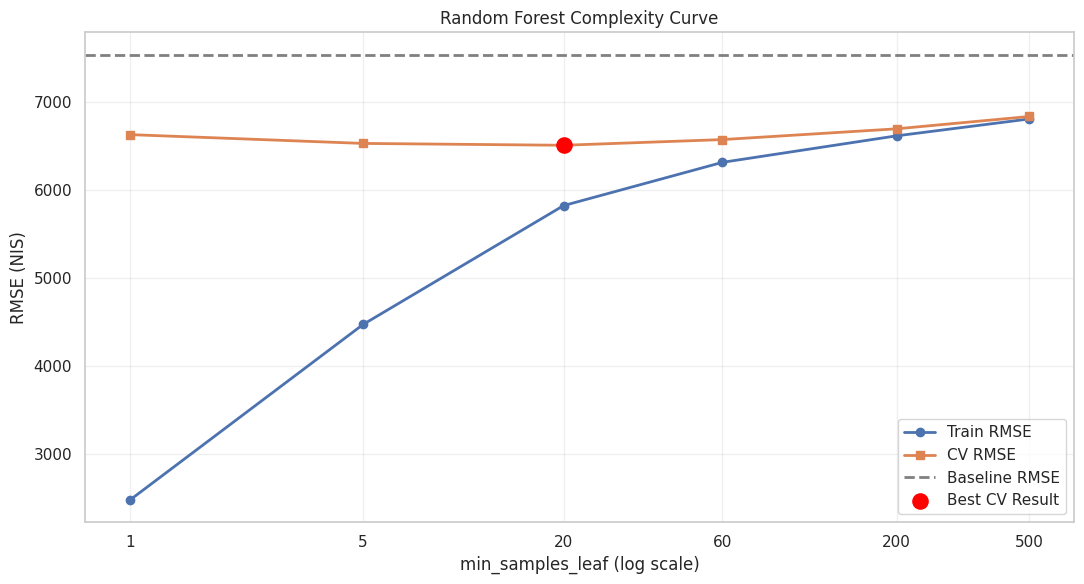

In [35]:

# יצירת גרף עקומת המורכבות
plt.figure(figsize=(11, 6))

# שגיאת האימון
plt.plot(
    complexity_df['min_samples_leaf'],
    complexity_df['Train RMSE'],
    marker='o',
    linewidth=2,
    label='Train RMSE'
)

# שגיאת Cross Validation
plt.plot(
    complexity_df['min_samples_leaf'],
    complexity_df['CV RMSE'],
    marker='s',
    linewidth=2,
    label='CV RMSE'
)

# קו Baseline - חיזוי הממוצע
plt.axhline(
    y=baseline_rmse,
    color='gray',
    linestyle='--',
    linewidth=2,
    label='Baseline RMSE'
)

# סימון הערך בעל שגיאת CV הנמוכה ביותר
best_idx = complexity_df['CV RMSE'].idxmin()
best_leaf = complexity_df.loc[best_idx, 'min_samples_leaf']
best_cv = complexity_df.loc[best_idx, 'CV RMSE']

plt.scatter(
    best_leaf,
    best_cv,
    color='red',
    s=120,
    zorder=5,
    label='Best CV Result'
)

# הגדרת ציר X לוגריתמי
plt.xscale('log')
plt.xticks(leaf_values, leaf_values)

# עיצוב הגרף
plt.title('Random Forest Complexity Curve')
plt.xlabel('min_samples_leaf (log scale)')
plt.ylabel('RMSE (NIS)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">

### **ניתוח עקומת המורכבות של Random Forest ובחירת המודל הסופי:**


<div dir="rtl" style="text-align: right;">

<p>
בחנו את השפעת הפרמטר
<code>min_samples_leaf</code>
על ביצועי מודל Random Forest.
</p>

<p>
נבדקו שישה ערכים: 1, 5, 20, 60, 200 ו-500.
עבור כל ערך חישבנו RMSE על נתוני האימון
ועל נתוני הוולידציה באמצעות 10-Fold Cross Validation.
</p>

<p>
בנוסף, חישבנו שגיאת Baseline של מודל
החוזה לכל נהג את ממוצע עלויות התביעות
בנתוני האימון. שגיאת ה-Baseline
שהתקבלה היא 7,538.29 ש"ח.
</p>

**א. באיזה ערך המודל מתחיל לשנן רעש?**

<p>
עדות חזקה ל-Overfitting מתקבלת כאשר
min_samples_leaf=1.
</p>

<p>
בערך זה שגיאת האימון היא 2,479.23 ש"ח,
בעוד ששגיאת ה-CV היא 6,628.52 ש"ח.
הפער הגדול, כ-4,149 ש"ח, מעיד על כך
שהמודל מתאים את עצמו היטב לנתוני האימון,
אך מתקשה להכליל לנתונים חדשים.
</p>

<p>
גם בערך 5 קיים פער משמעותי בין השגיאות.
לכן ניתן לזהות התאמת יתר בעיקר בערכים
הנמוכים שנבדקו, ובמיוחד בערך 1.
</p>

**ב. מה הפער בין שגיאת האימון לשגיאת ה-CV מלמד על הרעש בנתונים?**

<p>
כאשר העצים מורכבים מאוד, הם מסוגלים
ללמוד גם מאפיינים מקריים של נתוני האימון.
</p>

<p>
הפער הגדול בין שגיאת האימון לשגיאת ה-CV
מעיד על התאמת יתר ועל קושי בהכללה.
</p>

<p>
עלות התביעות עשויה להיות מושפעת גם
מאירועים מקריים ומגורמים שאינם מופיעים
בנתונים, ולכן חלק מהשונות עשוי להיות
קשה לחיזוי.
</p>

<p>
עם זאת, הפער בין השגיאות אינו מודד
ישירות את כמות הרעש במשתנה המטרה,
ולא ניתן לייחס את כולו לרעש בלבד.
</p>

**ג. איזה ערך נבחר למודל הסופי ולמה?**

<p>
נבחר בערך min_samples_leaf=20,
משום שהוא השיג את שגיאת ה-CV
הנמוכה ביותר מבין הערכים שנבדקו:
6,507.67 ש"ח.
</p>

<p>
לעומת זאת, הערך 1 השיג את שגיאת
האימון הנמוכה ביותר, אך שגיאת
הוולידציה שלו הייתה גבוהה יותר.
</p>

<p>
לכן נעדיף מודל שמצליח להכליל
לנתונים שלא ראה באימון,
ולא בהכרח מודל שמציג את
שגיאת האימון הנמוכה ביותר.
</p>

<p>
המודל שנבחר גם משפר את שגיאת ה-RMSE
בכ-1,030.62 ש"ח לעומת ה-Baseline,
שיפור של כ-13.67%.
</p>

**ד. מה היה משתנה אילו היו לנו פי שניים יותר נהגים?**

<p>
אם היו לנו פי שניים יותר נהגים,
בהנחה שהם מייצגים את אותה אוכלוסייה,
המודל היה יכול ללמוד מתוך מגוון רחב
יותר של דוגמאות.
</p>

<p>
ייתכן ששגיאת ה-CV הייתה יורדת,
במיוחד במודלים המורכבים,
ושהפער בין שגיאת האימון לשגיאת
הוולידציה היה מצטמצם.
</p>

<p>
כמות גדולה יותר של נתונים עשויה להפחית
את הסיכון להתאמת יתר ולאפשר שימוש
במודלים מורכבים יותר.
</p>

<p>
עם זאת, שיפור אינו מובטח,
משום שחלק מהשונות בעלויות התביעות
עשוי לנבוע מגורמים מקריים או
ממידע שאינו זמין למודל.
</p>

**מסקנה מסכמת:**

<p>
עקומת המורכבות מדגימה את האיזון
בין התאמת יתר (Overfitting)
לבין התאמת חסר (Underfitting).
</p>

<p>
בערכים נמוכים של min_samples_leaf
המודל מורכב מאוד ונוטה להתאמת יתר.
בערכים גבוהים מאוד, כמו 500,
המודל פשוט יותר ושתי השגיאות
גבוהות יחסית, דבר המצביע על התאמת חסר.
</p>

<p>
הערך 20 מספק את הביצועים הטובים ביותר
ב-Cross Validation מבין האפשרויות שנבדקו,
ולכן נבחר בו עבור מודל Random Forest הסופי.
</p>

</div>


<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**6. ניתוח שגיאות (Error Analysis)**</span>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**6.1 חילוץ הנהגים החריגים (Outliers)** (20 הנהגים עם שגיאות החיזוי הגדולות ביותר)</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה ננתח את שגיאות החיזוי של מודל Random Forest, שהשיג את הביצועים הטובים ביותר.

מתוך תחזיות ה-Cross Validation נחלץ:

- **10 תחזיות היתר הגדולות ביותר (Overprediction)** - מקרים שבהם התחזית גבוהה משמעותית מהעלות בפועל.
- **10 תחזיות החסר הגדולות ביותר (Underprediction)** - מקרים שבהם התחזית נמוכה משמעותית מהעלות בפועל.

בסך הכול נבחן 20 נהגים חריגים, כדי להבין את מאפייני השגיאות ואת מגבלות המודל.

</div>


In [36]:

# יצירת טבלה לניתוח שגיאות
rf_error_df = df[feature_columns + ['annual_claim_cost']].copy()

# יצירת מזהה שורה לצורך זיהוי הנהגים
rf_error_df = rf_error_df.reset_index(drop=True)
rf_error_df['driver_id'] = np.arange(len(rf_error_df))

# הוספת תחזיות Random Forest מתוך Cross Validation
rf_error_df['predicted_cost'] = rf_oof_pred

# חישוב שגיאת החיזוי: תחזית פחות ערך אמיתי
rf_error_df['error'] = (
    rf_error_df['predicted_cost'] -
    rf_error_df['annual_claim_cost']
)

# חישוב גודל השגיאה ללא סימן
rf_error_df['absolute_error'] = rf_error_df['error'].abs()

# עשרת הנהגים שהמודל העריך גבוה מדי
rf_over = rf_error_df.nlargest(10, 'error').copy()

# עשרת הנהגים שהמודל העריך נמוך מדי
rf_under = rf_error_df.nsmallest(10, 'error').copy()

# איחוד 20 הנהגים
rf_outliers = pd.concat([rf_over, rf_under])

# בחירת עמודות להצגת התוצאות
display_columns = [
    'driver_id',
    'driver_age',
    'country',
    'vehicle_type',
    'usage_type',
    'annual_claim_cost',
    'predicted_cost',
    'error'
]

print("Top 10 Overpredictions:")
display(rf_over[display_columns].round(2))

print("\nTop 10 Underpredictions:")
display(rf_under[display_columns].round(2))

# בדיקת מספר הנהגים
assert len(rf_outliers) == 20

print("\nTotal outliers:", len(rf_outliers))


Top 10 Overpredictions:


,driver_id,driver_age,country,vehicle_type,usage_type,annual_claim_cost,predicted_cost,error
10096,10096,22,US,sports,leisure,0,39019.22,39019.22
39357,39357,20,US,sports,leisure,0,36753.61,36753.61
22188,22188,20,US,sports,leisure,0,36676.38,36676.38
29167,29167,20,US,sports,leisure,0,35301.75,35301.75
42181,42181,19,US,sports,leisure,0,35075.10,35075.10
35395,35395,21,US,sports,leisure,0,34436.97,34436.97
1821,1821,31,US,suv,professional,0,33983.57,33983.57
43154,43154,22,US,sports,commute,0,33313.32,33313.32
18533,18533,43,US,pickup,commute,0,33299.23,33299.23
24133,24133,74,US,pickup,professional,0,33154.98,33154.98



Top 10 Underpredictions:


,driver_id,driver_age,country,vehicle_type,usage_type,annual_claim_cost,predicted_cost,error
37523,37523,23,US,pickup,professional,224808,34485.39,-190322.61
26042,26042,19,US,suv,leisure,156823,28087.25,-128735.75
28389,28389,56,US,suv,professional,143338,26936.55,-116401.45
8412,8412,33,US,sports,commute,140119,29081.55,-111037.45
18758,18758,39,US,sports,commute,128531,20404.47,-108126.53
3002,3002,27,US,suv,commute,126128,19270.49,-106857.51
21109,21109,58,US,pickup,commute,113288,7019.10,-106268.90
27457,27457,18,DE,sports,leisure,125734,20637.79,-105096.21
4876,4876,24,US,pickup,commute,126986,22155.24,-104830.76
37167,37167,18,IL,sports,leisure,123818,20428.57,-103389.43



Total outliers: 20


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**6.2 ניתוח איכותי של הנהגים החריגים וזיהוי דפוסים משותפים**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נבחן את המאפיינים המשותפים של 20 הנהגים בעלי שגיאות החיזוי הקיצוניות ביותר.

נשווה בין תחזיות יתר לתחזיות חסר, ונבחר חמישה נהגים לניתוח פרטני של מאפייניהם והסיבות האפשריות לשגיאות החיזוי.

</div>


<div dir="rtl" style="text-align: right;">

### **זיהוי דפוסים משותפים ובחירת חמישה נהגים לניתוח:**

In [37]:

# יצירת עותק של טבלת הנהגים החריגים
outliers_analysis = rf_outliers.copy()

# סיווג סוג השגיאה
outliers_analysis['error_type'] = np.where(
    outliers_analysis['error'] > 0,
    'Overprediction',
    'Underprediction'
)

# השוואת המאפיינים הכלליים של שתי הקבוצות
group_summary = outliers_analysis.groupby('error_type').agg(
    drivers_count=('driver_id', 'count'),
    mean_age=('driver_age', 'mean'),
    mean_actual_cost=('annual_claim_cost', 'mean'),
    mean_predicted_cost=('predicted_cost', 'mean'),
    mean_absolute_error=('absolute_error', 'mean')
)

print("Summary by Error Type:")
display(group_summary.round(2))

# השוואת התפלגות המדינות, סוגי הרכב והשימוש
for col in ['country', 'vehicle_type', 'usage_type']:

    print(f"\nDistribution by {col}:")

    display(
        pd.crosstab(
            outliers_analysis['error_type'],
            outliers_analysis[col]
        )
    )

# בדיקת שיעור הנהגים מארה"ב בכלל הדאטה
us_rate = (df['country'] == 'US').mean() * 100

print("\nUS drivers in full dataset:",
      round(us_rate, 2), "%")


# בחירת חמישה נהגים לניתוח פרטני
selected_drivers = [10096, 1821, 37523, 26042, 27457]

# מאפיינים שנבחן עבור כל נהג
profile_columns = [
    'driver_age',
    'country',
    'license_years',
    'prior_claims_5y',
    'violations_3y',
    'vehicle_type',
    'vehicle_age',
    'vehicle_value',
    'usage_type',
    'annual_km_estimated',
    'pct_night_driving',
    'annual_claim_cost',
    'predicted_cost',
    'error'
]

# הצגת פרופיל מפורט עבור חמשת הנהגים
driver_profiles = (
    outliers_analysis
    .set_index('driver_id')
    .loc[selected_drivers, profile_columns]
    .T
)

print("\nSelected Driver Profiles:")
display(driver_profiles)


Summary by Error Type:


,drivers_count,mean_age,mean_actual_cost,mean_predicted_cost,mean_absolute_error
error_type,,,,,
Overprediction,10,29.2,0.0,35101.41,35101.41
Underprediction,10,31.5,140957.3,22850.64,118106.66



Distribution by country:


country,DE,IL,US
error_type,,,
Overprediction,0,0,10
Underprediction,1,1,8



Distribution by vehicle_type:


vehicle_type,pickup,sports,suv
error_type,,,
Overprediction,2,7,1
Underprediction,3,4,3



Distribution by usage_type:


usage_type,commute,leisure,professional
error_type,,,
Overprediction,2,6,2
Underprediction,5,3,2



US drivers in full dataset: 22.02 %

Selected Driver Profiles:


driver_id,10096,1821,37523,26042,27457
driver_age,22,31,23,19,18
country,US,US,US,US,DE
license_years,4,10,5,0,0
prior_claims_5y,2.0,6.0,4.0,NaN,NaN
violations_3y,1,0,1,0,0
vehicle_type,sports,suv,pickup,suv,sports
vehicle_age,2,1,2,3,7
vehicle_value,264000,229000,138500,123000,255000
usage_type,leisure,professional,professional,leisure,leisure
annual_km_estimated,6000.0,999999.0,NaN,11500.0,6500.0


<div dir="rtl" style="text-align: right;">

### **ניתוח איכותי של שגיאות החיזוי:**


<div dir="rtl" style="text-align: right;">

<p>
לאחר חילוץ 20 הנהגים עם שגיאות החיזוי
הקיצוניות ביותר במודל Random Forest,
בחנו את מאפייניהם במטרה לזהות דפוסים
משותפים ולנסות להבין את הגורמים האפשריים
לשגיאות.
</p>

**ניתוח חמישה נהגים ספציפיים:**

<p>
<b>נהג 10096 – Overprediction:</b>
</p>

<p>
נהג בן 22 מארה"ב, בעל רכב ספורט
בשווי 264,000 ש"ח, עם שתי תביעות קודמות
ועבירת תנועה אחת.
המודל חזה עלות של 39,019.22 ש"ח,
אך העלות בפועל הייתה 0 ש"ח.
ייתכן שמאפייני הסיכון שלו הובילו
לתחזית גבוהה, אך המודל אינו יכול לדעת
בוודאות האם תתרחש תביעה בשנת הביטוח.
</p>

<p>
<b>נהג 1821 – Overprediction:</b>
</p>

<p>
נהג בן 31 מארה"ב, בעל רכב SUV,
המשמש לנהיגה מקצועית, עם שש תביעות
קודמות בחמש השנים האחרונות.
המודל חזה 33,983.57 ש"ח, אך בפועל
לא הייתה עלות תביעות.
בנוסף, הקילומטראז' הגולמי שלו היה
999999, ערך שהוגדר כחסר בעיבוד הנתונים;
ייתכן שהיסטוריית התביעות והשימוש המקצועי
השפיעו על התחזית הגבוהה.
</p>

<p>
<b>נהג 37523 – Underprediction:</b>
</p>

<p>
נהג בן 23 מארה"ב, בעל רכב Pickup,
המשמש לנהיגה מקצועית, עם ארבע תביעות
קודמות ועבירת תנועה אחת.
עלות התביעות בפועל הייתה 224,808 ש"ח,
בעוד שהמודל חזה 34,485.39 ש"ח בלבד.
ייתכן שהמודל זיהה סיכון מוגבר,
אך לא הצליח לחזות את חומרתו החריגה
של האירוע או את עלות התביעות הגבוהה במיוחד.
</p>

<p>
<b>נהג 26042 – Underprediction:</b>
</p>

<p>
נהג בן 19 מארה"ב, בעל רכב SUV,
ללא שנות רישיון מדווחות, כאשר מידע
על תביעות קודמות חסר.
המודל חזה עלות של 28,087.25 ש"ח,
לעומת עלות בפועל של 156,823 ש"ח.
ייתכן שהיעדר מידע על היסטוריית התביעות,
יחד עם חוסר היכולת לדעת מראש
את חומרת התביעה, תרמו לשגיאה הגדולה.
</p>

<p>
<b>נהג 27457 – Underprediction:</b>
</p>

<p>
נהג בן 18 מגרמניה, בעל רכב ספורט
בשווי 255,000 ש"ח, עם אפס שנות רישיון
ומידע חסר על תביעות קודמות.
המודל חזה עלות של 20,637.79 ש"ח,
אך העלות בפועל הייתה 125,734 ש"ח.
ייתכן שמאפייני הנהג והרכב הצביעו
על סיכון מסוים, אך לא הספיקו כדי
לחזות עלות תביעות קיצונית כל כך.
</p>

**דפוסים משותפים בין 20 הנהגים:**

<p>
<b>1. מאפיינים גאוגרפיים:</b>
</p>

<p>
כל עשרת הנהגים עם שגיאות Overprediction
הקיצוניות ביותר הם מארה"ב.
גם שמונה מתוך עשרת הנהגים עם שגיאות
Underprediction הם מארה"ב.
</p>

<p>
זאת אף שנהגים מארה"ב מהווים רק 22.02%
מכלל הדאטה.
ריכוז זה מצביע על דפוס שדורש בדיקה,
אך אינו מוכיח כשלעצמו הטיה של המודל.
</p>

<p>
<b>2. מאפייני הרכב:</b>
</p>

<p>
שבעה מתוך עשרת הנהגים עם Overprediction
נוהגים ברכבי ספורט.
לעומת זאת, בקבוצת Underprediction
נמצאו ארבעה רכבי ספורט, שלושה רכבי SUV
ושלושה רכבי Pickup.
</p>

<p>
הדבר עשוי להצביע על קשר בין מאפייני
הרכב לבין שגיאות חיזוי קיצוניות,
אך יש להשוות זאת גם לשכיחות סוגי
הרכב בכלל הדאטה.
</p>

<p>
<b>3. סוג השימוש ברכב:</b>
</p>

<p>
בקבוצת Overprediction, שישה נהגים
משתמשים ברכב לפנאי, שניים לנסיעה
לעבודה ושניים לנהיגה מקצועית.
</p>

<p>
בקבוצת Underprediction, חמישה נהגים
משתמשים ברכב לנסיעה לעבודה,
שלושה לפנאי ושניים לנהיגה מקצועית.
</p>

<p>
לא זוהה סוג שימוש יחיד המאפיין
את כל הנהגים בעלי השגיאות הקיצוניות.
</p>

**הבדלים בין Overprediction ל-Underprediction**

<p>
בכל עשרת מקרי ה-Overprediction,
עלות התביעות בפועל הייתה אפס,
אך המודל חזה עלויות גבוהות.
ייתכן שהמודל זיהה מאפייני סיכון
הקשורים לעלות צפויה גבוהה,
אף שבשנת הפוליסה לא נגרמה
עלות תביעות בפועל.
</p>

<p>
לעומת זאת, בעשרת מקרי ה-Underprediction
נרשמו עלויות תביעות גבוהות במיוחד.
העלות הממוצעת בפועל בקבוצה זו
הייתה 140,957.30 ש"ח,
בעוד שהתחזית הממוצעת הייתה
22,850.64 ש"ח בלבד.
</p>

<p>
הממצא עשוי להעיד על קושי של מודל
הרגרסיה לחזות את גודלן של תביעות
חריגות ונדירות.
</p>

**מה המודל אינו יודע?**

<p>
המודל מבוסס על מאפיינים הידועים
לפני תחילת שנת הביטוח.
הוא אינו יודע מראש אם תתרחש תאונה,
מה תהיה חומרתה ומה תהיה עלות הנזק.
</p>

<p>
לכן גם נהגים בעלי מאפייני סיכון
גבוהים עשויים לסיים שנה ללא תביעות,
ומנגד נהגים עם תחזית מתונה עשויים
לגרום לעלויות גבוהות במיוחד.
</p>

**מסקנה:**

<p>
ניתוח השגיאות מצביע על שני אתגרים מרכזיים:
חיזוי עלויות גבוהות לנהגים שבפועל
לא גרמו לתביעות, והערכת חסר
של תביעות יקרות במיוחד.
</p>

<p>
בנוסף, נמצא ריכוז גבוה של נהגים
מארה"ב בשתי קבוצות השגיאה,
המצדיק בחינה נוספת של ביצועי המודל
לפי מדינה במסגרת ניתוח ההוגנות.
</p>

<p>
חשוב להדגיש כי הניתוח מבוסס על
20 המקרים הקיצוניים ביותר בלבד.
לכן הממצאים מאפשרים להעלות השערות,
אך אינם מוכיחים קשר סיבתי
או חוסר הוגנות של המודל.
</p>

</div>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**6.3 השוואת השגיאות בין Elastic Net ל-Random Forest**</span>




<div dir="rtl" style="text-align: right;">

בסעיף זה נשווה בין 20 הנהגים בעלי שגיאות החיזוי הגדולות ביותר בכל אחד משני המודלים.

נבחן:

- כמה נהגים חריגים משותפים לשני המודלים.
- האם מודל אחד מצליח לחזות טוב יותר נהגים שהמודל השני טועה לגביהם.
- אילו סוגי שגיאות מאפיינים כל מודל.

מטרת ההשוואה היא להבין האם השגיאות נובעות ממגבלות המודל או מקושי מהותי בחיזוי עלויות תביעות חריגות.

</div>

In [38]:

# יצירת טבלה להשוואת שגיאות שני המודלים
comparison_df = pd.DataFrame({
    'driver_id': np.arange(len(df)),
    'actual_cost': df['annual_claim_cost'].to_numpy(),
    'elastic_pred': elastic_oof_pred,
    'rf_pred': rf_oof_pred
})

# חישוב השגיאות של שני המודלים
comparison_df['elastic_error'] = (
    comparison_df['elastic_pred'] -
    comparison_df['actual_cost']
)

comparison_df['rf_error'] = (
    comparison_df['rf_pred'] -
    comparison_df['actual_cost']
)

# חישוב השגיאות המוחלטות
comparison_df['elastic_abs_error'] = (
    comparison_df['elastic_error'].abs()
)

comparison_df['rf_abs_error'] = (
    comparison_df['rf_error'].abs()
)

# חילוץ 10 שגיאות חיוביות ו-10 שליליות לכל מודל
elastic_over = comparison_df.nlargest(
    10, 'elastic_error'
)
elastic_under = comparison_df.nsmallest(
    10, 'elastic_error'
)

rf_over_compare = comparison_df.nlargest(
    10, 'rf_error'
)
rf_under_compare = comparison_df.nsmallest(
    10, 'rf_error'
)

# איחוד 20 הנהגים הקיצוניים של כל מודל
elastic_top20 = pd.concat([
    elastic_over, elastic_under
])

rf_top20 = pd.concat([
    rf_over_compare, rf_under_compare
])

# זיהוי נהגים משותפים לשני המודלים
elastic_ids = set(elastic_top20['driver_id'])
rf_ids = set(rf_top20['driver_id'])

common_ids = elastic_ids.intersection(rf_ids)

print("Elastic Net outliers:", len(elastic_ids))
print("Random Forest outliers:", len(rf_ids))
print("Common outliers:", len(common_ids))
print("Common driver IDs:", sorted(common_ids))

# בדיקת חפיפה לפי סוג השגיאה
common_over = set(elastic_over['driver_id']) & set(
    rf_over_compare['driver_id']
)

common_under = set(elastic_under['driver_id']) & set(
    rf_under_compare['driver_id']
)

print("\nCommon Overpredictions:", len(common_over))
print("Common Underpredictions:", len(common_under))


# בדיקת איזה מודל טעה פחות בכל נהג
comparison_df['better_model'] = np.where(
    comparison_df['elastic_abs_error'] <
    comparison_df['rf_abs_error'],
    'Elastic Net',
    np.where(
        comparison_df['rf_abs_error'] <
        comparison_df['elastic_abs_error'],
        'Random Forest',
        'Tie'
    )
)

# עמודות להצגת השוואת השגיאות
compare_columns = [
    'driver_id',
    'actual_cost',
    'elastic_pred',
    'rf_pred',
    'elastic_abs_error',
    'rf_abs_error',
    'better_model'
]

print("\nElastic Net - Top 20 Outliers:")
display(
    comparison_df[
        comparison_df['driver_id'].isin(elastic_ids)
    ][compare_columns].round(2)
)

print("\nRandom Forest - Top 20 Outliers:")
display(
    comparison_df[
        comparison_df['driver_id'].isin(rf_ids)
    ][compare_columns].round(2)
)

# בדיקת המודל המדויק יותר על הנהגים הקיצוניים
for model_name, ids in [
    ('Elastic Net', elastic_ids),
    ('Random Forest', rf_ids)
]:

    subset = comparison_df[
        comparison_df['driver_id'].isin(ids)
    ]

    print(f"\nWhen examining {model_name} outliers:")
    print(subset['better_model'].value_counts())


Elastic Net outliers: 20
Random Forest outliers: 20
Common outliers: 8
Common driver IDs: [3002, 4876, 8412, 18758, 26042, 27457, 28389, 37523]

Common Overpredictions: 0
Common Underpredictions: 8

Elastic Net - Top 20 Outliers:


,driver_id,actual_cost,elastic_pred,rf_pred,elastic_abs_error,rf_abs_error,better_model
3002,3002,126128,13703.32,19270.49,112424.68,106857.51,Random Forest
3838,3838,125853,16464.78,38690.74,109388.22,87162.26,Random Forest
4876,4876,126986,15665.86,22155.24,111320.14,104830.76,Random Forest
8412,8412,140119,20626.84,29081.55,119492.16,111037.45,Random Forest
11048,11048,0,21188.15,12204.10,21188.15,12204.10,Random Forest
12747,12747,0,27511.17,32900.10,27511.17,32900.10,Elastic Net
14470,14470,0,21255.75,24327.15,21255.75,24327.15,Elastic Net
15010,15010,0,21971.35,11830.34,21971.35,11830.34,Random Forest
18758,18758,128531,18415.52,20404.47,110115.48,108126.53,Random Forest
22629,22629,126009,15880.95,30473.35,110128.05,95535.65,Random Forest



Random Forest - Top 20 Outliers:


,driver_id,actual_cost,elastic_pred,rf_pred,elastic_abs_error,rf_abs_error,better_model
1821,1821,0,16820.44,33983.57,16820.44,33983.57,Elastic Net
3002,3002,126128,13703.32,19270.49,112424.68,106857.51,Random Forest
4876,4876,126986,15665.86,22155.24,111320.14,104830.76,Random Forest
8412,8412,140119,20626.84,29081.55,119492.16,111037.45,Random Forest
10096,10096,0,16350.24,39019.22,16350.24,39019.22,Elastic Net
18533,18533,0,15750.88,33299.23,15750.88,33299.23,Elastic Net
18758,18758,128531,18415.52,20404.47,110115.48,108126.53,Random Forest
21109,21109,113288,8717.94,7019.10,104570.06,106268.90,Elastic Net
22188,22188,0,12594.38,36676.38,12594.38,36676.38,Elastic Net
24133,24133,0,17725.02,33154.98,17725.02,33154.98,Elastic Net



When examining Elastic Net outliers:
better_model
Random Forest    18
Elastic Net       2
Name: count, dtype: int64

When examining Random Forest outliers:
better_model
Elastic Net      11
Random Forest     9
Name: count, dtype: int64


<div dir="rtl" style="text-align: right;">

### **השוואה איכותית של שגיאות שני המודלים:**


<div dir="rtl" style="text-align: right;">

<p>
השווינו את 20 הנהגים עם שגיאות החיזוי
הקיצוניות ביותר בכל אחד מהמודלים,
באמצעות תחזיות Out-of-Fold שהתקבלו
בתהליך Cross Validation.
</p>

**1. חפיפה בין הנהגים החריגים**

<p>
מתוך 20 הנהגים החריגים של כל מודל,
נמצאו 8 נהגים משותפים לשתי הרשימות.
</p>

<p>
כל שמונת הנהגים המשותפים הופיעו
בקבוצת ה-Underprediction.
לא נמצאה חפיפה בין קבוצות
ה-Overprediction הקיצוניות של שני המודלים.
</p>

<p>
הממצא מצביע על כך ששני המודלים
מתקשים בחיזוי חלק מאותן תביעות
יקרות במיוחד, למרות ההבדלים
במבנה המודלים.
</p>

**2. האם המודל השני מצליח יותר?**

<p>
מבין 20 הנהגים החריגים של Elastic Net,
מודל Random Forest הציג שגיאה מוחלטת
נמוכה יותר ב-18 מקרים.
</p>

<p>
לעומת זאת, מבין 20 הנהגים החריגים
של Random Forest, מודל Elastic Net
הציג שגיאה מוחלטת נמוכה יותר ב-11 מקרים,
ואילו Random Forest היה מדויק יותר
בתשעת המקרים האחרים.
</p>

<p>
כלומר, יתרונו הכללי של Random Forest
אינו מתקיים בהכרח עבור כל נהג.
</p>

**3. דוגמאות להשוואה בין המודלים:**

<p>
<b>נהג 37523 - תביעת ענק:</b>
</p>

<p>
עלות התביעות בפועל הייתה 224,808 ש"ח.
Elastic Net חזה 16,904.24 ש"ח,
ואילו Random Forest חזה 34,485.39 ש"ח.
שני המודלים העריכו את העלות בחסר משמעותי,
אך Random Forest היה קרוב יותר לערך האמיתי.
</p>

<p>
<b>נהג 10096 - הערכת סיכון גבוהה מדי:</b>
</p>

<p>
עלות התביעות בפועל הייתה 0 ש"ח.
Elastic Net חזה 16,350.24 ש"ח,
ואילו Random Forest חזה 39,019.22 ש"ח.
במקרה זה Elastic Net היה מדויק יותר,
בעוד Random Forest העריך את העלות
גבוה מדי בפער משמעותי.
</p>

<p>
<b>נהג 2109 - מקרה שבו Elastic Net הצליח יותר:</b>
</p>

<p>
עלות התביעות בפועל הייתה 113,288 ש"ח.
Elastic Net חזה 8,717.94 ש"ח,
לעומת תחזית של 7,019.10 ש"ח
ב-Random Forest.
שני המודלים העריכו את העלות בחסר,
אך שגיאת Elastic Net הייתה קטנה יותר.
</p>

**4. סוגי שגיאות המאפיינים כל מודל:**

<p>
<b>Elastic Net:</b>
</p>

<p>
בכל עשרת מקרי ה-Underprediction
הקיצוניים שלו, Random Forest הציג
שגיאה קטנה יותר.
</p>

<p>
ממצא זה מתאים לאפשרות שהמודל הליניארי
מתקשה לייצג חלק מהקשרים המורכבים
הקשורים לעלויות תביעה גבוהות.
</p>

<p>
<b>Random Forest:</b>
</p>

<p>
בכל עשרת מקרי ה-Overprediction
הקיצוניים שלו, Elastic Net הציג
שגיאה מוחלטת נמוכה יותר.
</p>

<p>
במקרים אלה העלות בפועל הייתה אפס,
אך Random Forest חזה עלויות גבוהות.
ייתכן שהמודל מזהה שילובים של מאפייני סיכון
ומעניק להם תחזיות גבוהות,
גם כאשר לא התרחשה תביעה בפועל.
</p>

**5. מסקנות מההשוואה:**

<p>
ההשוואה מראה שלשני המודלים
חוזקות וחולשות שונות.
</p>

<p>
Random Forest מצליח בדרך כלל יותר
בחיזוי עלויות התביעות לפי מדדי
ה-Cross Validation הכלליים,
אך Elastic Net מדויק יותר בחלק
ממקרי הערכת היתר הקיצוניים
של Random Forest.
</p>

<p>
בנוסף, שני המודלים מתקשים
בחיזוי תביעות יקרות במיוחד,
כנראה משום שחומרתן של תביעות חריגות
אינה ניתנת להסבר מלא באמצעות
המאפיינים הקיימים בדאטה.
</p>

<p>
חשוב להדגיש שההשוואה מתמקדת
במקרים קיצוניים שנבחרו לפי גודל השגיאה.
לכן לא ניתן להסיק ממנה איזה מודל
מדויק יותר לכלל הנהגים.
לשם כך נסתמך על מדדי ה-Cross Validation.
</p>

</div>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**6.4 הצעות לשיפור המודל בעקבות ניתוח השגיאות**</span>



<div dir="rtl" style="text-align: right;">

בהתבסס על ניתוח 20 הנהגים החריגים והשוואת השגיאות בין Elastic Net ל-Random Forest, נציע שלושה פיצ'רים חדשים שעשויים לשפר את יכולת החיזוי:

1. **`prior_claims_per_year`** – שיעור התביעות הקודמות ביחס לשנות הנהיגה הרלוונטיות, כדי לייצג את תדירות התביעות ולא רק את מספרן.

2. **`vehicle_usage_interaction`** – שילוב בין שווי הרכב לסוג השימוש בו, כדי לזהות קשרים בין מאפייני הרכב לבין החשיפה לסיכון.

3. **`prior_claims_missing`** – משתנה בינארי המציין אם המידע על תביעות קודמות חסר, כדי לבדוק אם עצם היעדר המידע עשוי לסייע בחיזוי.

פיצ'רים אלו מוצעים לשיפור עתידי ולא נכללו במודלים שאומנו. כדי לקבוע אם הם אכן מועילים, יש לבדוק אותם באמצעות Cross Validation.

</div>


<div dir="rtl" style="text-align: right;">

### **הצעות לפיצ'רים חדשים לשיפור המודל:**


<div dir="rtl" style="text-align: right;">


<p>
בהתבסס על ניתוח שגיאות החיזוי של Elastic Net
ו-Random Forest, זיהינו מאפיינים שחזרו
בקרב נהגים בעלי שגיאות קיצוניות.
</p>

<p>
נציע שלושה פיצ'רים חדשים, שלא נכללו
במודלים המקוריים, במטרה לשפר את היכולת
לזהות הבדלים ברמת הסיכון בין נהגים.
</p>

**1. prior_claims_per_year - תדירות תביעות קודמות ביחס לוותק הנהיגה**

<p>
<b>נוסחה:</b>
</p>

<p dir="ltr" style="text-align: left;">
prior_claims_5y / min(license_years, 5)
</p>

<p>
החישוב יבוצע רק כאשר שנות הרישיון חיוביות
והיסטוריית התביעות זמינה.
במקרים אחרים יישמר ערך חסר.
</p>

<p>
<b>מוטיבציה:</b>
מספר התביעות הקודמות לבדו אינו מביא בחשבון
את משך הזמן שבו הנהג מחזיק ברישיון.
יחס התביעות לוותק הרלוונטי עשוי לספק
מדד מדויק יותר לתדירות התביעות הקודמות.
</p>

<p>
לדוגמה, נהג 37523, בעל ארבע תביעות קודמות
וחמש שנות רישיון, גרם לעלות תביעות חריגה
שהמודלים העריכו בחסר.
ייתכן שפיצ'ר המתאר את תדירות התביעות
יעזור למודל לזהות רמות סיכון שונות.
</p>

**2. vehicle_usage_interaction - שילוב סוג הרכב וסוג השימוש**

<p>
<b>נוסחה:</b>
</p>

<p dir="ltr" style="text-align: left;">
vehicle_type + "_" + usage_type
</p>

<p>
<b>מוטיבציה:</b>
סוג הרכב וסוג השימוש עשויים להשפיע יחד
על רמת הסיכון של הנהג.
לדוגמה, רכב Pickup המשמש לנהיגה מקצועית
עשוי להיות בעל מאפייני סיכון שונים
מאותו רכב המשמש לפנאי.
</p>

<p>
בניתוח השגיאות זיהינו מספר נהגים
עם שילובים חוזרים, כגון רכבי ספורט
המשמשים לפנאי ורכבי Pickup
המשמשים לנהיגה מקצועית.
</p>

<p>
פיצ'ר משולב עשוי לאפשר למודל לזהות
דפוסים ספציפיים לשילובים אלו.
עם זאת, נצטרך לבדוק האם השילוב אכן
מוסיף מידע מעבר למשתנים המקוריים.
</p>

**3. prior_claims_missing - אינדיקציה להיסטוריית תביעות חסרה**

<p>
<b>נוסחה:</b>
</p>

<p dir="ltr" style="text-align: left;">
prior_claims_5y.isna().astype(int)
</p>

<p>
<b>מוטיבציה:</b>
במילון השדות מצוין כי היסטוריית
התביעות עשויה להיות חסרה אצל נהגים
חדשים או במדינות שבהן הרישום חלקי.
</p>

<p>
לכן, עצם העובדה שהמידע חסר
עשויה להכיל מידע מנבא,
מעבר לערך שהיה מתקבל בהשלמת הנתון.
</p>

<p>
לדוגמה, אצל הנהגים 26042 ו-27457,
ששניהם הופיעו במקרי ה-Underprediction,
חסר מידע על תביעות קודמות.
</p>

<p>
אינדיקטור לחוסר המידע עשוי לעזור
למודל להבחין בין נהג ללא תביעות קודמות
לבין נהג שהיסטוריית התביעות שלו אינה ידועה.
</p>

**מניעת Data Leakage:**

<p>
שלושת הפיצ'רים מבוססים על נתונים
שאמורים להיות זמינים לפני תחילת הפוליסה.
</p>

<p>
הם אינם משתמשים בעלות התביעות של שנת
הביטוח הנחזית או במידע שנוצר במהלכה.
</p>

<p>
אם נחליט לממש אותם, ניצור אותם
בפונקציית prepare_data,
ואת השלמת הערכים החסרים והקידוד
נבצע בתוך ה-Pipeline.
</p>

**מסקנה:**

<p>
הפיצ'רים המוצעים מתמקדים בשלושה היבטים:
תדירות תביעות קודמות, שילוב מאפייני הרכב
והשימוש בו, וזמינות היסטוריית התביעות.
</p>

<p>
ייתכן שהם יסייעו למודל לזהות דפוסים
שהפיצ'רים הקיימים אינם מייצגים היטב.
עם זאת, תרומתם לחיזוי היא השערה
שיש לבחון באמצעות Cross Validation
לפני אימוצם בפועל.
</p>

</div>


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**6.5 סימון נהגים יקרים באמצעות - Precision ו-Recall**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נגדיר כלל לזיהוי נהגים שצפויים לגרום לעלות תביעות שנתית גבוהה מ-10,000 ש"ח.

הכלל יתבסס על תחזיות ה-Cross Validation של מודל Random Forest:

**נהג יסומן כיקר אם עלות התביעות החזויה שלו גבוהה מ-10,000 ש"ח.**

נבחן את איכות הכלל באמצעות שני מדדים:

- **Precision** - שיעור הנהגים היקרים באמת מתוך כלל הנהגים שסומנו כיקרים.
- **Recall** - שיעור הנהגים היקרים שזוהו נכון מתוך כלל הנהגים היקרים בפועל.

ננתח את התוצאות ונבחן האם הכלל מתאים לשימוש עסקי בחברת הביטוח.

</div>


In [39]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix
)

# הגדרת סף לסימון נהג יקר
threshold = 10000

# הסיווג האמיתי לפי עלות התביעות בפועל
y_true_expensive = (y.to_numpy() > threshold).astype(int)

# הסיווג החזוי לפי תחזיות Random Forest
y_pred_expensive = (rf_oof_pred > threshold).astype(int)

# חישוב Precision ו-Recall
precision = precision_score(
    y_true_expensive,
    y_pred_expensive,
    zero_division=0
)

recall = recall_score(
    y_true_expensive,
    y_pred_expensive,
    zero_division=0
)

# חישוב מטריצת בלבול
tn, fp, fn, tp = confusion_matrix(
    y_true_expensive,
    y_pred_expensive,
    labels=[0, 1]
).ravel()

# הצגת התוצאות
print("Threshold:", threshold, "NIS")

print("\nPrecision:", round(precision, 4))
print("Recall:", round(recall, 4))

print("\nPrecision (%):", round(precision * 100, 2))
print("Recall (%):", round(recall * 100, 2))

print("\nConfusion Matrix:")
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Negatives:", tn)

# הצגת מספר הנהגים היקרים
print("\nActual expensive drivers:",
      y_true_expensive.sum())

print("Predicted expensive drivers:",
      y_pred_expensive.sum())


Threshold: 10000 NIS

Precision: 0.5102
Recall: 0.2698

Precision (%): 51.02
Recall (%): 26.98

Confusion Matrix:
True Positives: 1122
False Positives: 1077
False Negatives: 3037
True Negatives: 39764

Actual expensive drivers: 4159
Predicted expensive drivers: 2199


<div dir="rtl" style="text-align: right;">

### **ניתוח Precision ו־Recall לזיהוי נהגים יקרים:**


<div dir="rtl" style="text-align: right;">

<p>
בהתאם לסעיף 6.5, הגדרנו כלל לזיהוי נהגים
שעלות התביעות השנתית שלהם צפויה להיות
גבוהה מ-10,000 ש"ח.
</p>

<p>
הכלל מבוסס על התחזית המספרית של Random Forest:
נהג יסומן כיקר אם עלות התביעות החזויה
גבוהה מ-10,000 ש"ח.
</p>

<p>
הערכת הכלל התבצעה באמצעות תחזיות
Out-of-Fold שהתקבלו ב-10-Fold Cross Validation.
</p>

**תוצאות הכלל:**

<ul>
<li><b>Precision:</b> 51.02%</li>
<li><b>Recall:</b> 26.98%</li>
<li><b>True Positives:</b> 1,122</li>
<li><b>False Positives:</b> 1,077</li>
<li><b>False Negatives:</b> 3,037</li>
<li><b>True Negatives:</b> 39,764</li>
</ul>

**פרשנות התוצאות:**

<p>
מתוך 2,199 הנהגים שסומנו כיקרים על ידי
המודל, 1,122 היו יקרים בפועל.
לכן התקבל Precision של 51.02%.
</p>

<p>
לעומת זאת, מתוך 4,159 נהגים שהיו
יקרים בפועל, המודל זיהה רק 1,122.
לכן התקבל Recall של 26.98%.
</p>

<p>
משמעות הדבר היא שהמודל מצליח לזהות
קבוצה שבה שיעור הנהגים היקרים גבוה
משמעותית משיעורם בכלל הדאטה (9.24%),
אך מחמיץ כ-73% מהנהגים היקרים בפועל.
</p>

**המשמעות העסקית:**

<p>
מבחינת חברת הביטוח, False Negative
מייצג נהג שלא סומן כיקר, למרות
שעלות התביעות שלו הייתה גבוהה מ-10,000 ש"ח.
</p>

<p>
שגיאות מסוג זה עלולות להוביל להערכת חסר
של הסיכון הביטוחי.
</p>

<p>
לעומת זאת, False Positive מייצג נהג
שסומן כיקר, למרות שעלות התביעות
שלו בפועל לא עברה את הסף.
</p>

<p>
שימוש בסימון כזה בהחלטות אוטומטיות
עלול להוביל להערכת יתר של הסיכון,
ולכן נדרשת זהירות.
</p>

**נימוק בחירת הסף:**

<p>
בחרנו בסף של 10,000 ש"ח משום
שהוא תואם להגדרה העסקית של נהג יקר
שניתנה בהנחיות המטלה.
</p>

<p>
הסף נקבע מראש ולא כוונן על תחזיות
הוולידציה, כדי להימנע מבחירת סף
שמוטה לתוצאות המדגם.
</p>

<p>
עם זאת, שיעור ה-Recall הנמוך מעיד
שהכלל אינו מתאים לשמש לבדו
כמערכת שמטרתה לזהות את מרבית
הנהגים היקרים.
</p>

**הצעה לשיפור:**

<p>
ניתן לשקול שימוש בסף חיזוי נמוך יותר
כדי לנסות להגדיל את שיעור ה-Recall.
</p>

<p>
עם זאת, הורדת הסף עשויה להגדיל
גם את מספר ה-False Positives
ולפגוע ב-Precision.
</p>

<p>
לכן, בחירת סף חלופי צריכה להתבצע
בהתאם לעלויות העסקיות של סוגי הטעויות,
ובאמצעות הליך ולידציה נפרד.
</p>

**מסקנה:**

<p>
הכלל שנבחר מצליח לזהות קבוצה בעלת
שיעור גבוה יחסית של נהגים יקרים,
אך מפספס את רוב הנהגים היקרים בפועל.
</p>

<p>
לכן, ניתן לשקול שימוש בסימון
לצורך תעדוף בדיקות נוספות,
אך לא כהחלטה אוטומטית על קבלת
או דחיית לקוחות.
</p>

</div>


<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**7. ניתוח הוגנות (Fairness Analysis)**</span>





<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**7.1 השוואת ביצועי המודל לפי קבוצות נהגים**</span>

<div dir="rtl" style="text-align: right;">

בסעיף זה נבחן האם מודל Random Forest מציג רמת דיוק דומה עבור קבוצות שונות של נהגים.

 נחשב את מדדי RMSE ו-MAE בשלושה חתכים:

- **מגדר:** נשים (F) לעומת גברים (M).
- **מדינה:** השוואת ביצועי המודל בין מדינות.
- **קבוצות גיל:** 18–24, 25–64 ו-65 ומעלה.

נשתמש בתחזיות Out-of-Fold שהתקבלו ב-10-Fold Cross Validation.

מטרת הניתוח היא לזהות קבוצות שבהן שגיאות החיזוי גבוהות במיוחד ולבחון האם קיימים פערי ביצועים משמעותיים.

</div>


In [40]:

# יצירת טבלה לניתוח הוגנות
fairness_df = pd.DataFrame({
    'gender': X['gender'].to_numpy(),
    'country': X['country'].to_numpy(),
    'driver_age': X['driver_age'].to_numpy(),
    'actual_cost': y.to_numpy(),
    'predicted_cost': rf_oof_pred
})

# חלוקה לקבוצות גיל לפי הנחיות המטלה
fairness_df['age_group'] = pd.cut(
    fairness_df['driver_age'],
    bins=[-np.inf, 24, 64, np.inf],
    labels=['18-24', '25-64', '65+']
)

# חישוב שגיאות לכל נהג
fairness_df['error'] = (
    fairness_df['predicted_cost'] -
    fairness_df['actual_cost']
)

fairness_df['absolute_error'] = (
    fairness_df['error'].abs()
)

fairness_df['squared_error'] = (
    fairness_df['error'] ** 2
)

# חישוב המדדים הכלליים מתוך תחזיות ה-CV
overall_rmse = np.sqrt(
    fairness_df['squared_error'].mean()
)

overall_mae = fairness_df['absolute_error'].mean()

print("Overall OOF RMSE:", round(overall_rmse, 2))
print("Overall OOF MAE:", round(overall_mae, 2))


# פונקציה לחישוב מדדים לפי קבוצות
def fairness_by_group(data, group_col):

    result = data.groupby(
        group_col, observed=True
    ).agg(
        drivers_count=('error', 'count'),
        mean_squared_error=('squared_error', 'mean'),
        MAE=('absolute_error', 'mean')
    )

    # חישוב RMSE לכל קבוצה
    result['RMSE'] = np.sqrt(
        result['mean_squared_error']
    )

    # הפרש באחוזים ביחס למדד הכללי
    result['RMSE_diff_%'] = (
        (result['RMSE'] / overall_rmse - 1) * 100
    )

    result['MAE_diff_%'] = (
        (result['MAE'] / overall_mae - 1) * 100
    )

    # בחירת העמודות לתצוגה
    result = result[[
        'drivers_count',
        'RMSE',
        'MAE',
        'RMSE_diff_%',
        'MAE_diff_%'
    ]]

    return result.round(2)


# ניתוח לפי מגדר
gender_fairness = fairness_by_group(
    fairness_df, 'gender'
)

print("\nFairness by Gender:")
display(gender_fairness)


# ניתוח לפי מדינה
country_fairness = fairness_by_group(
    fairness_df, 'country'
)

print("\nFairness by Country:")
display(country_fairness)


# ניתוח לפי קבוצות גיל
age_fairness = fairness_by_group(
    fairness_df, 'age_group'
)

print("\nFairness by Age Group:")
display(age_fairness)


Overall OOF RMSE: 6518.43
Overall OOF MAE: 3458.6

Fairness by Gender:


,drivers_count,RMSE,MAE,RMSE_diff_%,MAE_diff_%
gender,,,,,
F,20762,5989.77,3205.36,-8.11,-7.32
M,24238,6939.33,3675.52,6.46,6.27



Fairness by Country:


,drivers_count,RMSE,MAE,RMSE_diff_%,MAE_diff_%
country,,,,,
BR,3156,2235.15,1469.65,-65.71,-57.51
DE,5789,6223.42,3472.60,-4.53,0.40
ES,3739,3601.25,1985.69,-44.75,-42.59
FR,4536,4516.85,2608.75,-30.71,-24.57
GB,5394,4712.24,2604.61,-27.71,-24.69
IL,4455,5690.81,3291.91,-12.70,-4.82
IT,4508,4132.21,2330.13,-36.61,-32.63
JP,1335,2673.93,1631.15,-58.98,-52.84
PL,2181,2346.19,1573.05,-64.01,-54.52



Fairness by Age Group:


,drivers_count,RMSE,MAE,RMSE_diff_%,MAE_diff_%
age_group,,,,,
18-24,3542,10090.36,5022.84,54.80,45.23
25-64,33205,6216.68,3405.17,-4.63,-1.54
65+,8253,5700.00,3002.23,-12.56,-13.20


<div dir="rtl" style="text-align: right;">

## <span dir="rtl" style="display:block; text-align:right;">**7.2 דיון בממצאי ההוגנות והשפעת ערכים חסרים**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נדון בתוצאות ניתוח ההוגנות ונבחן את המשמעות שלהן עבור חברת הביטוח.

נתייחס לארבע שאלות מרכזיות:

1. **פערי דיוק:** באילו קבוצות המודל פחות מדויק, ובכמה אחוזים ביחס לביצועים הכלליים?

2. **הסברים אפשריים:** האם הפערים קשורים לכמות נתונים, לרעש בנתונים או להבדלים בין מקורות המידע?

3. **השלכות עסקיות:** עבור אילו קבוצות נהגים נדרשת זהירות מיוחדת בהסתמכות על תחזיות המודל?

4. **ערכים חסרים (Missingness):** האם היעדר נתונים מסוימים קשור לשגיאות גבוהות יותר, והאם הוא עשוי להעיד על הטיה?

נבחן במיוחד את ההבדלים בין נהגים עם נתוני נסועה שנתית והיסטוריית תביעות תקינים לבין נהגים שעבורם נתונים אלו חסרים.

</div>


<div dir="rtl" style="text-align: right;">

### **ניתוח הוגנות ופערי דיוק בין קבוצות:**


<div dir="rtl" style="text-align: right;">

<p>
בחנו את ביצועי מודל Random Forest בשלושה חתכים:
מגדר, מדינה וקבוצת גיל, בהתאם לדרישות המטלה.
</p>

<p>
הניתוח התבסס על תחזיות Out-of-Fold
שהתקבלו באמצעות 10-Fold Cross Validation.
עבור כל קבוצה חישבנו RMSE ו-MAE,
והשווינו אותם למדדי השגיאה הכלליים.
</p>

<p>
ערך ה-RMSE הכללי הוא 6,518.43 ש"ח,
וערך ה-MAE הכללי הוא 3,458.60 ש"ח.
</p>

**1. ניתוח לפי מגדר**

<p>
בקרב נשים התקבל RMSE של 5,989.77 ש"ח
ו-MAE של 3,205.36 ש"ח.
לעומת זאת, בקרב גברים התקבל RMSE
של 6,939.33 ש"ח ו-MAE של 3,675.52 ש"ח.
</p>

<p>
ה-RMSE של הגברים גבוה ב-6.46%
מה-RMSE הכללי, בעוד שאצל נשים
הוא נמוך ב-8.11% מהמדד הכללי.
</p>

<p>
הפער בין גברים לנשים ב-RMSE הוא
כ-949.56 ש"ח.
כלומר, שגיאת החיזוי בקבוצת הגברים
גבוהה בכ-15.85% ביחס לקבוצת הנשים.
</p>

<p>
התוצאות מצביעות על הבדל ברמת הדיוק
בין קבוצות המגדר.
עם זאת, אין בכך הוכחה לאפליה,
משום שהפער עשוי להיות קשור גם
להבדלים במאפייני הנהגים ובהתפלגות
עלויות התביעות בכל קבוצה.
</p>

**2. ניתוח לפי מדינה**

<p>
הפער המשמעותי ביותר נמצא בחלוקה לפי מדינה.
בקרב נהגים מארה"ב התקבל RMSE של
10,860.14 ש"ח, הגבוה ב-66.61%
מהמדד הכללי.
</p>

<p>
גם ה-MAE בארה"ב גבוה במיוחד ועומד
על 6,743.78 ש"ח, כ-94.99% מעל
הממוצע הכללי.
</p>

<p>
לעומת זאת, במדינות אחרות נמצאו
שגיאות נמוכות בהרבה.
לדוגמה, בברזיל התקבל RMSE של
2,235.15 ש"ח, ובגרמניה RMSE
של 6,223.42 ש"ח.
</p>

<p>
הממצא תואם את ניתוח השגיאות שביצענו,
שבו 18 מתוך 20 הנהגים עם השגיאות
הקיצוניות ביותר היו מארה"ב,
אף שנהגים מארה"ב מהווים רק 22.02%
מכלל הנתונים.
</p>

<p>
ייתכן שהפער קשור להתפלגות שונה של
עלויות התביעות, לשיעור גבוה יותר
של תביעות יקרות במיוחד או
להבדלים במאפייני הנהגים והרכבים.
</p>

<p>
עם זאת, לא בדקנו עדיין איזו מההשערות
הללו מסבירה את הפער, ולכן לא ניתן
לקבוע את סיבתו בוודאות.
</p>

**3. ניתוח לפי קבוצות גיל**

<p>
בקבוצת גיל 18–24 התקבל RMSE של
10,090.36 ש"ח, הגבוה ב-54.80%
מהמדד הכללי.
ה-MAE בקבוצה זו הוא 5,022.84 ש"ח,
גבוה ב-45.23% מהמדד הכללי.
</p>

<p>
בקבוצת גיל 25–64 התקבל RMSE
של 6,216.68 ש"ח, הנמוך ב-4.63%
מהממוצע הכללי.
</p>

<p>
בקבוצת גיל 65 ומעלה התקבל RMSE
של 5,700 ש"ח, הנמוך ב-12.56%
מהמדד הכללי.
</p>

<p>
לכן, נראה כי המודל מתקשה במיוחד
בחיזוי עלויות התביעות של נהגים צעירים.
</p>

<p>
ממצא זה מתאים לחקירת הנתונים הראשונית,
שבה מצאנו עלויות תביעות גבוהות יותר
בקרב נהגים צעירים.
</p>

**4. סיבות אפשריות לפערי הדיוק**

<p>
פערים בין קבוצות עשויים לנבוע ממספר גורמים:
</p>

<ul>
<li>
הבדלים בהתפלגות עלויות התביעות
ובשכיחות תביעות יקרות במיוחד.
</li>

<li>
הבדלים בגודל קבוצות הנתונים
ובמספר הדוגמאות הזמינות לאימון.
</li>

<li>
הבדלים במאפייני הנהגים, הרכבים
והרגלי השימוש בהם.
</li>

<li>
הבדלים בזמינות ובאיכות המידע,
כגון היסטוריית תביעות חסרה
או קילומטראז' שלא דווח.
</li>
</ul>

<p>
אלו הסברים אפשריים בלבד.
נדרשות בדיקות נוספות כדי לקבוע
אילו גורמים אכן משפיעים על הפערים.
</p>

**5. השלכות על השימוש במודל**

<p>
הפערים שנמצאו מעלים חשש לגבי
שימוש במודל לצורך קבלת החלטות
ביטוחיות באופן אוטומטי.
</p>

<p>
בפרט, נדרשת זהירות בהסתמכות
על תחזיות עבור נהגים מארה"ב
ונהגים בגילאי 18–24,
שבהם נמצאו שגיאות גבוהות יחסית.
</p>

<p>
מומלץ לשלב בדיקות נוספות,
להעריך את רמת אי-הוודאות של התחזית
ולבחון את איכות המודל בכל קבוצה
לפני קבלת החלטות המשפיעות על לקוחות.
</p>

<p>
חשוב להדגיש כי פער בשגיאת החיזוי
אינו מוכיח הטיה מפלה.
כדי לבחון הוגנות לעומק יש להתייחס
גם להתפלגות הסיכון ולמאפייני הקבוצות.
</p>

**6. השפעת ערכים חסרים - Missingness**

<p>
בנתונים קיימים ערכים חסרים
בהיסטוריית התביעות ובקילומטראז' השנתי.
לפי מילון השדות, חלק מהחוסרים
קשורים לנהגים חדשים ולרישום חלקי במדינות שונות.
</p>

<p>
לכן, ייתכן שעצם היעדר המידע
מכיל מידע מנבא ואף קשור לפערי
הדיוק שנצפו בין קבוצות.
</p>

<p>
עדיין לא בדקנו באופן כמותי
האם שגיאות המודל שונות בין
נהגים עם נתונים חסרים
לבין נהגים שהמידע שלהם מלא.
</p>

<p>
נבצע בדיקה נוספת של השפעת החוסרים
כדי להבין האם הם קשורים
לפערי הדיוק ולחששות להטיה.
</p>

**מסקנה מסכמת:**

<p>
ניתוח ההוגנות הראה שביצועי המודל
אינם אחידים בין קבוצות הנהגים.
</p>

<p>
הפערים הגדולים ביותר נמצאו
בקרב נהגים מארה"ב ונהגים צעירים.
בנוסף, נמצאו הבדלים ברמת הדיוק
בין גברים לנשים.
</p>

<p>
לכן, לפני שימוש מעשי במודל,
יש לבחון את הגורמים לפערים,
לבדוק את השפעת הנתונים החסרים
ולוודא שההחלטות הביטוחיות אינן
מתבססות על תחזיות שאינן מהימנות
עבור קבוצות מסוימות.
</p>

</div>


<div dir="rtl" style="text-align: right;">

### **השפעת ערכים חסרים על דיוק המודל (Missingness Analysis):**

In [41]:

# יצירת טבלה לבדיקת השפעת ערכים חסרים
missingness_df = fairness_df.copy()

# סימון קילומטראז' חסר או לא תקין לאחר הניקוי
missingness_df['km_missing'] = (
    X['annual_km_estimated'].isna().to_numpy()
)

# סימון היסטוריית תביעות חסרה
missingness_df['claims_missing'] = (
    X['prior_claims_5y'].isna().to_numpy()
)

# יצירת קבוצות לפי זמינות המידע
missingness_df['km_status'] = np.where(
    missingness_df['km_missing'],
    'Missing or Invalid',
    'Available'
)

missingness_df['claims_status'] = np.where(
    missingness_df['claims_missing'],
    'Missing',
    'Available'
)

# השוואת שגיאות לפי זמינות הקילומטראז'
print("Fairness by Annual KM Availability:")

km_fairness = fairness_by_group(
    missingness_df, 'km_status'
)

display(km_fairness)

# השוואת שגיאות לפי זמינות היסטוריית התביעות
print("\nFairness by Prior Claims Availability:")

claims_fairness = fairness_by_group(
    missingness_df, 'claims_status'
)

display(claims_fairness)


# בדיקת שיעור הערכים החסרים לפי מדינה ומגדר
for group_col in ['country', 'gender']:

    missing_rates = missingness_df.groupby(
        group_col, dropna=False
    ).agg(
        drivers_count=('error', 'size'),
        missing_km_pct=('km_missing', 'mean'),
        missing_claims_pct=('claims_missing', 'mean')
    )

    # המרת שיעורים לאחוזים
    missing_rates[
        ['missing_km_pct', 'missing_claims_pct']
    ] *= 100

    print(f"\nMissing Values by {group_col}:")
    display(missing_rates.round(2))


Fairness by Annual KM Availability:


,drivers_count,RMSE,MAE,RMSE_diff_%,MAE_diff_%
km_status,,,,,
Available,39303,6092.16,3277.50,-6.54,-5.24
Missing or Invalid,5697,8920.51,4708.01,36.85,36.12



Fairness by Prior Claims Availability:


,drivers_count,RMSE,MAE,RMSE_diff_%,MAE_diff_%
claims_status,,,,,
Available,41858,6405.23,3447.30,-1.74,-0.33
Missing,3142,7872.75,3609.17,20.78,4.35



Missing Values by country:


,drivers_count,missing_km_pct,missing_claims_pct
country,,,
BR,3156,15.49,20.56
DE,5789,11.83,4.51
ES,3739,12.76,8.21
FR,4536,10.80,4.63
GB,5394,9.08,4.73
IL,4455,9.94,5.25
IT,4508,14.24,8.03
JP,1335,8.16,4.27
PL,2181,17.01,14.86



Missing Values by gender:


,drivers_count,missing_km_pct,missing_claims_pct
gender,,,
F,20762,12.71,6.94
M,24238,12.62,7.02


<div dir="rtl" style="text-align: right;">

### **ניתוח השפעת ערכים חסרים על דיוק המודל וההוגנות:**


<div dir="rtl" style="text-align: right;">

<p>
בהמשך לניתוח ההוגנות, בחנו האם זמינות המידע
משפיעה על רמת הדיוק של Random Forest,
והאם קיימים הבדלים בדפוסי החוסר בין קבוצות נהגים.
</p>

<p>
הבדיקה התמקדה בשני משתנים:
<code>annual_km_estimated</code> ו-
<code>prior_claims_5y</code>.
הניתוח התבסס על תחזיות Out-of-Fold.
</p>

**1. השפעת זמינות הקילומטראז'**

<p>
בקרב 39,303 נהגים עם נתון קילומטראז' זמין,
התקבל RMSE של 6,092.16 ש"ח
ו-MAE של 3,277.50 ש"ח.
</p>

<p>
לעומת זאת, בקרב 5,697 נהגים שהנתון שלהם
חסר או סומן כלא תקין, התקבל RMSE
של 8,920.51 ש"ח ו-MAE של 4,708.01 ש"ח.
</p>

<p>
ביחס לשגיאה הכללית, ה-RMSE בקבוצת
הנתונים החסרים גבוה ב-36.85%,
לעומת RMSE הנמוך ב-6.54% מהממוצע
בקבוצת הנהגים עם נתון זמין.
</p>

<p>
הפער הישיר בין הקבוצות הוא כ-46.4%
ב-RMSE, ומעיד על קשר משמעותי
בין זמינות הקילומטראז' לבין דיוק החיזוי.
</p>

<p>
עם זאת, לא ניתן לקבוע שהיעדר הקילומטראז'
הוא הגורם לשגיאות הגבוהות,
משום שייתכן שהנהגים בקבוצות שונים
גם במאפייני סיכון אחרים.
</p>

**2. השפעת זמינות היסטוריית התביעות**

<p>
בקרב 41,858 נהגים עם היסטוריית תביעות זמינה,
התקבל RMSE של 6,405.23 ש"ח
ו-MAE של 3,447.30 ש"ח.
</p>

<p>
בקרב 3,142 נהגים שהיסטוריית התביעות
שלהם חסרה, התקבל RMSE של 7,872.75 ש"ח
ו-MAE של 3,609.17 ש"ח.
</p>

<p>
ה-RMSE בקבוצת הנתונים החסרים
גבוה ב-20.78% מהמדד הכללי.
</p>

<p>
התוצאות מצביעות על קשר בין
חוסר בהיסטוריית התביעות לבין
שגיאות חיזוי גבוהות יותר,
בעיקר לפי מדד RMSE.
</p>

<p>
ממצא זה מחזק את ההצעה מסעיף 6.4
ליצור פיצ'ר המציין האם
היסטוריית התביעות חסרה.
עם זאת, עדיין לא הוכחנו
שפיצ'ר כזה ישפר את המודל.
</p>

**3. השוואת דפוסי חוסר לפי מדינה**

<p>
נמצאו הבדלים בזמינות המידע בין המדינות.
</p>

<p>
לדוגמה, בפולין שיעור החוסרים
בקילומטראז' הוא 17.01%,
לעומת 8.16% ביפן.
</p>

<p>
בהיסטוריית התביעות, שיעור החוסרים
בברזיל הוא 20.56% ובפולין 14.88%,
לעומת 4.88% בארה"ב.
</p>

<p>
המשמעות היא שדפוסי חוסר אינם אחידים
בכל המדינות ועשויים לשקף הבדלים
באופן איסוף הנתונים ובזמינותם.
</p>

<p>
עם זאת, למרות ששגיאת החיזוי בארה"ב
גבוהה במיוחד, שיעור החוסרים
בהיסטוריית התביעות שם אינו גבוה.
לכן לא ניתן להסביר את פערי הדיוק
בין המדינות באמצעות חוסר המידע בלבד.
</p>

**4. השוואת דפוסי חוסר לפי מגדר**

<p>
שיעור החוסרים בקילומטראז'
הוא 12.71% בקרב נשים ו-12.62% בקרב גברים.
</p>

<p>
בהיסטוריית התביעות, שיעור החוסרים
הוא 6.94% בקרב נשים ו-7.02% בקרב גברים.
</p>

<p>
מדובר בהבדלים קטנים מאוד.
לכן לא נמצאה עדות להבדל משמעותי
בדפוסי החוסר של שני המשתנים
בין קבוצות המגדר.
</p>

<p>
מכאן שהפערים ברמת הדיוק בין גברים לנשים
אינם מוסברים באופן ברור
על ידי שיעורי החוסר שבדקנו.
</p>

**5. האם Missingness עשוי להיות מנבא?**

<p>
התוצאות מצביעות על כך שזמינות המידע
קשורה לרמת שגיאת החיזוי.
</p>

<p>
לכן ייתכן שאינדיקטורים לערכים חסרים
יוכלו להוסיף מידע מועיל למודל,
מעבר להשלמת הערכים באמצעות החציון.
</p>

<p>
לדוגמה, ניתן להוסיף משתנה בינארי
המציין אם הקילומטראז' השנתי חסר,
או אם היסטוריית התביעות אינה זמינה.
</p>

<p>
עם זאת, יש לבדוק את תרומת המשתנים
באמצעות Cross Validation,
ולא להניח מראש שהם ישפרו את הביצועים.
</p>

**6. השלכות על ההוגנות והשימוש במודל**

<p>
הבדלים בזמינות המידע בין מדינות
עשויים להשפיע על איכות החיזוי
וליצור פערים עקיפים בין קבוצות.
</p>

<p>
בפרט, יש לנקוט זהירות בעת שימוש
בתחזיות עבור נהגים שמידע חשוב לגביהם חסר,
מכיוון שבקבוצות אלה נצפו
שגיאות חיזוי גבוהות יותר.
</p>

<p>
עם זאת, פערים בשגיאה אינם מוכיחים
אפליה או קשר סיבתי.
נדרשת בחינה נוספת של מאפייני הקבוצות,
התפלגות עלויות התביעות ואיכות הנתונים.
</p>

**מסקנה מסכמת:**

<p>
מצאנו קשר בין חוסר במידע
לבין שגיאות חיזוי גבוהות יותר,
במיוחד כאשר הקילומטראז' השנתי
חסר או אינו תקין.
</p>

<p>
בנוסף, דפוסי החוסר משתנים בין מדינות,
אך כמעט אינם משתנים בין מגדרים.
</p>

<p>
ממצאים אלו מדגישים את החשיבות
של איכות הנתונים ושל בדיקת ביצועי
המודל בנפרד עבור קבוצות שונות,
לפני שימוש בו בהחלטות ביטוחיות.
</p>

</div>


<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**8. הערכה על נתוני מבחן חיצוניים (Held-Out Test Set)**</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נכין את מודל Elastic Net להגשה ונבדוק את תקינות תהליך החיזוי על נתונים חדשים.

בהתאם להנחיות המרצה, במעמד הבדיקה ייטען קובץ CSV המכיל 5,000 נהגים שלא השתתפו באימון, ללא עמודת המטרה.

תהליך ההפעלה הנדרש הוא:

`X = prepare_data(df_test)`

`y_pred = model.predict(X)`

נבדוק שהמודל השמור בקובץ `model.pkl` נטען בהצלחה ומפיק תחזיות תקינות.

בדיקת התקינות המקומית מתבצעת על רשומות מתוך הנתונים הקיימים, ולכן אינה מהווה הערכת ביצועים על סט המבחן החיצוני של המרצה.

</div>


<div dir="rtl" style="text-align: right;">

### **אימון ושמירת מודל Elastic Net הסופי:**

In [42]:

import joblib

# בחירת מודל Elastic Net הסופי
final_elastic_model = refined_grid_search.best_estimator_

# הצגת הפרמטרים שנבחרו
print("Final Elastic Net Parameters:")
print(refined_grid_search.best_params_)

# שמירת המודל המאומן, כולל ה-Pipeline
joblib.dump(final_elastic_model, 'model.pkl')

print("\nModel saved successfully!")

# טעינת המודל מהקובץ
loaded_model = joblib.load('model.pkl')

# יצירת נתוני בדיקה ללא משתנה המטרה
test_df = df.drop(columns=['annual_claim_cost']).iloc[:100].copy()

# עיבוד הנתונים באמצעות prepare_data
X_test = prepare_data(test_df)

# ביצוע תחזיות באמצעות המודל השמור
y_pred_test = loaded_model.predict(X_test)

# בדיקות תקינות
assert len(y_pred_test) == 100
assert np.isfinite(y_pred_test).all()
assert X_test.columns.tolist() == X.columns.tolist()

# בדיקה על נהג בודד
single_test = prepare_data(test_df.iloc[[0]])
single_pred = loaded_model.predict(single_test)

assert len(single_pred) == 1

print("Prediction test passed!")
print("Single driver prediction:", round(single_pred[0], 2))

# הצגת חמש תחזיות ראשונות
display(pd.DataFrame({
    'Predicted Claim Cost': y_pred_test[:5]
}).round(2))


Final Elastic Net Parameters:
{'model__alpha': 0.01, 'model__l1_ratio': 0.95}

Model saved successfully!
Prediction test passed!
Single driver prediction: 2728.68


,Predicted Claim Cost
0,2728.68
1,297.04
2,-1271.62
3,998.75
4,5324.50


<div dir="rtl" style="text-align: right;">

### **בדיקת עמידות המודל על נתונים חדשים:**

In [43]:

# יצירת נתוני בדיקה ללא משתנה המטרה
test_raw = df.drop(
    columns=['annual_claim_cost']
).iloc[:100].copy()

# יצירת נהג בודד עם ערכים חריגים
new_driver = test_raw.iloc[[0]].copy()

# קטגוריות חדשות שלא הופיעו באימון
new_driver['gender'] = 'unknown'
new_driver['country'] = 'XX'
new_driver['vehicle_type'] = 'flying_car'

# ערכים חסרים ולא תקינים
new_driver['prior_claims_5y'] = np.nan
new_driver['has_telematics'] = 2
new_driver['annual_km_estimated'] = 999999
new_driver['engine_hp'] = 0

# שווי רכב שמופיע כטקסט
new_driver['vehicle_value'] = '1,000,000'

# בדיקת התמודדות עם עמודה חסרה
new_driver = new_driver.drop(
    columns=['parking_type']
)

# עיבוד באמצעות prepare_data
X_new = prepare_data(new_driver)

# חיזוי באמצעות המודל השמור
new_prediction = loaded_model.predict(X_new)

# בדיקות תקינות
assert X_new.shape == (1, 28)
assert X_new.columns.tolist() == X.columns.tolist()
assert 'annual_claim_cost' not in X_new.columns
assert np.isfinite(new_prediction).all()

# בדיקה על 100 נהגים
X_batch = prepare_data(test_raw)
batch_predictions = loaded_model.predict(X_batch)

assert len(batch_predictions) == 100
assert np.isfinite(batch_predictions).all()

# בדיקת דטרמיניסטיות
X_repeat = prepare_data(new_driver)
pd.testing.assert_frame_equal(X_new, X_repeat)

print("Single driver test: PASSED")
print("Batch test: PASSED")
print("Unknown categories test: PASSED")
print("Missing values test: PASSED")
print("Deterministic test: PASSED")

print("\nNew driver prediction:",
      round(new_prediction[0], 2))


Single driver test: PASSED
Batch test: PASSED
Unknown categories test: PASSED
Missing values test: PASSED
Deterministic test: PASSED

New driver prediction: 27415.98


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


<div dir="rtl" style="text-align: right;">

### **תיעוד בדיקות העמידות ומגבלות המודל:**


<div dir="rtl" style="text-align: right;">

<h3>בדיקות תקינות ועמידות של המודל הסופי</h3>

<p>
לאחר אימון מודל Elastic Net ושמירתו בקובץ
<code>model.pkl</code>, ביצענו בדיקות
כדי לוודא שהמודל ופונקציית
<code>prepare_data(df)</code>
מסוגלים להתמודד עם קלט חדש.
</p>

**בדיקות שבוצעו:**

<ul>
<li>
<b>נהג בודד:</b>
וידאנו שהפונקציה והמודל פועלים
גם כאשר מתקבלת תצפית אחת בלבד.
</li>

<li>
<b>מספר נהגים:</b>
בדקנו חיזוי עבור 100 נהגים והתקבלו
100 תחזיות מספריות תקינות.
</li>

<li>
<b>קטגוריות חדשות:</b>
הכנסנו בכוונה ערכים שלא הופיעו באימון,
כגון מדינה וסוג רכב לא מוכרים.
המודל הצליח להפיק תחזית ללא שגיאה.
</li>

<li>
<b>ערכים חסרים ולא תקינים:</b>
בדקנו היסטוריית תביעות חסרה,
קילומטראז' חשוד ועוצמת מנוע אפס.
הפונקציה טיפלה בערכים בהתאם
לכללי הניקוי שהוגדרו.
</li>

<li>
<b>עמודה חסרה:</b>
הסרנו את עמודת parking_type
ווידאנו שהפונקציה מחזירה את
מבנה העמודות הנדרש למודל.
</li>

<li>
<b>דטרמיניסטיות:</b>
הפעלנו את prepare_data פעמיים על
אותו קלט ווידאנו שהתקבלו תוצאות זהות.
</li>
</ul>

**תוצאות הבדיקות:**

<p>
כל חמש בדיקות התקינות עברו בהצלחה.
עבור נהג הבדיקה שהכיל ערכים לא מוכרים
וחסרים, התקבלה תחזית של 27,415.98 ש"ח.
</p>

<p>
תחזית זו משמשת לבדיקת תקינות טכנית בלבד,
ואינה מעידה על דיוק המודל עבור הנהג.
</p>

**התמודדות עם קטגוריות לא מוכרות:**

<p>
במהלך הבדיקה התקבלה אזהרה של
OneHotEncoder על קטגוריות שלא הופיעו באימון.
</p>

<p>
מאחר שהגדרנו
<code>handle_unknown='ignore'</code>,
הקטגוריות קודדו כאפסים
והמודל המשיך לפעול.
</p>

<p>
עם זאת, קידוד כזה אינו מבטיח
תחזית מדויקת עבור קטגוריות חדשות,
ויש להתייחס לכך כמגבלה.
</p>

**מגבלת התחזיות השליליות:**

<p>
בבדיקות הקודמות זיהינו שמודל Elastic Net
עשוי להחזיר גם תחזיות שליליות,
למרות שעלות תביעות אינה יכולה
להיות נמוכה מאפס.
</p>

<p>
מגבלה זו נובעת מכך שמודל הרגרסיה
הליניארי אינו מגביל את טווח התחזיות.
</p>

<p>
ניתן לבחון בהמשך הגבלת תחזיות שליליות
לאפס, אך שינוי כזה מחייב בדיקה מחודשת
של ביצועי המודל באמצעות Cross Validation.
</p>

**מסקנה:**

<p>
בדיקות העמידות אישרו שהמודל השמור
ופונקציית prepare_data מסוגלים לפעול
על קלטים המדמים נתונים חדשים,
כולל נהג בודד, ערכים חסרים
וקטגוריות לא מוכרות.
</p>
</div>
<div dir="rtl" style="text-align: right;">

#### בדיקות העמידות בוצעו באמצעות נתונים מתוך מערך הנתונים הקיים, לרבות קלט ללא משתנה המטרה, ערכים חסרים וקטגוריות לא מוכרות. הבדיקות נועדו לוודא את תקינות פונקציית prepare_data ואת יכולתו של המודל השמור להפיק תחזיות. הן אינן מהוות הערכת ביצועים על מערך המבחן החיצוני, שיועמד לרשות המרצה בלבד.


<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">**9. דוח הפרויקט (Report)**</span>



<div dir="rtl" style="text-align: right;">

בהתאם להנחיות המטלה, תוצאות הפרויקט מסוכמות בדוח נפרד בשם `report.pdf'

הדוח כולל:

- תיאור הנתונים והפיצ'רים שהונדסו.
- חקירת הנתונים והאסטרטגיה לפי גיל.
- תיעוד `prepare_data` ומניעת Data Leakage.
- השוואת המודלים, פרשנות Elastic Net ועקומת המורכבות.
- ניתוח שגיאות וזיהוי נהגים יקרים.
- ניתוח הוגנות וערכים חסרים.
- מסקנות, מגבלות והצעות לשיפור.
- נספח AI Usage Log המתעד את השימוש בכלי בינה מלאכותית ואת אימות התוצאות.

</div>


<div dir="rtl" style="text-align: right;">

### **שמירת תוצאות הניתוח לצורך הכנת הדוח:**

In [44]:

import os
import shutil
from google.colab import files

# יצירת תיקייה לשמירת תוצאות הפרויקט
os.makedirs('report_materials', exist_ok=True)

# ריכוז הטבלאות שכבר חישבנו
report_tables = {
    'age_summary': age_summary,
    'elastic_cv_results': elastic_cv_df,
    'elastic_summary': elastic_summary,
    'rf_cv_results': rf_cv_df,
    'rf_summary': rf_summary,
    'complexity_curve': complexity_df,
    'fairness_gender': gender_fairness,
    'fairness_country': country_fairness,
    'fairness_age': age_fairness,
    'fairness_km': km_fairness,
    'fairness_claims': claims_fairness,
    'rf_outliers': rf_outliers
}

# שמירת כל טבלה כקובץ CSV
for name, table in report_tables.items():

    table.to_csv(
        f'report_materials/{name}.csv',
        encoding='utf-8-sig'
    )

# שמירת תחזיות Cross Validation
# כדי שלא נצטרך לאמן את המודלים מחדש
np.savez_compressed(
    'report_materials/oof_predictions.npz',
    actual=y.to_numpy(),
    elastic_pred=elastic_oof_pred,
    rf_pred=rf_oof_pred
)

# שמירת ערך ה-Baseline
with open('report_materials/baseline.txt', 'w') as f:
    f.write(f'Baseline RMSE: {baseline_rmse:.2f}')

# יצירת קובץ ZIP מכל התוצאות
shutil.make_archive(
    'report_materials',
    'zip',
    'report_materials'
)

print("Report materials saved successfully!")
print("Tables saved:", len(report_tables))
print("OOF predictions: SAVED")
print("Baseline: SAVED")

# הורדת קובץ התוצאות למחשב
files.download('report_materials.zip')


Report materials saved successfully!
Tables saved: 12
OOF predictions: SAVED
Baseline: SAVED


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div dir="rtl" style="text-align: right;">

# <span dir="rtl" style="display:block; text-align:right;">10. דרישות הגשה (Submission Requirements)</span>



<div dir="rtl" style="text-align: right;">

בסעיף זה נכין ונבדוק את הקבצים הנדרשים להגשת הפרויקט.

**קבצי ההגשה:**

1. `notebook.ipynb` - מחברת הכוללת את הקוד, המודלים, ההערכה, ניתוח השגיאות וניתוח ההוגנות.
2. `model.pkl` - מודל Elastic Net המאומן, כולל תהליך העיבוד המקדים.
3. `report.pdf` - דוח הפרויקט.
4. `README.md` - תיאור הפרויקט והוראות הרצה.
5. `requirements.txt` - רשימת הספריות והגרסאות.

</div>


<div dir="rtl" style="text-align: right;">

### **בדיקה סופית והורדת model.pkl:**

In [ ]:

import os
import joblib
from google.colab import files

# טעינת המודל השמור
model = joblib.load('model.pkl')

# וידוא שהמודל הוא Elastic Net
assert isinstance(
    model.named_steps['model'],
    ElasticNet
)

# יצירת קלט בדיקה של 5,000 נהגים ללא משתנה המטרה
df_test = (
    df.drop(columns=['annual_claim_cost'])
    .sample(n=5000, random_state=42)
)

# הדמיית תהליך הבדיקה של המרצה
X_test = prepare_data(df_test)
y_pred = model.predict(X_test)

# בדיקות תקינות
assert X_test.shape == (5000, 28)
assert len(y_pred) == 5000
assert np.isfinite(y_pred).all()
assert 'annual_claim_cost' not in X_test.columns

print("Model type: ElasticNet")
print("Test rows:", len(X_test))
print("Predictions:", len(y_pred))
print("All predictions are finite: PASSED")

# הצגת גודל הקובץ
file_size = os.path.getsize('model.pkl') / 1024

print("\nModel file size:",
      round(file_size, 2), "KB")

print("\nFinal model test: PASSED")

# הורדת המודל למחשב
files.download('model.pkl')


Model type: ElasticNet
Test rows: 5000
Predictions: 5000
All predictions are finite: PASSED

Model file size: 7.96 KB

Final model test: PASSED


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div dir="rtl" style="text-align: right;">

### **יצירת קובץ requirements.txt:**

In [ ]:

from importlib.metadata import version
from google.colab import files
import sys

# הספריות הנדרשות לפרויקט
packages = [
    'pandas',
    'numpy',
    'matplotlib',
    'seaborn',
    'scikit-learn',
    'scipy',
    'joblib'
]

# שמירת הגרסאות המותקנות בקולאב
with open('requirements.txt', 'w') as f:
    for package in packages:
        f.write(f'{package}=={version(package)}\n')

# הצגת גרסת Python
print("Python version:", sys.version.split()[0])

# הצגת תוכן הקובץ
print("\nRequirements:")
with open('requirements.txt', 'r') as f:
    print(f.read())

# הורדת הקובץ למחשב
files.download('requirements.txt')


Python version: 3.13.18

Requirements:
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
scipy==1.16.3
joblib==1.6.0



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div dir="rtl" style="text-align: right;">

### **יצירת קובץ README.md:**

In [ ]:

from google.colab import files

# יצירת תוכן קובץ README
readme_content = """# חיזוי עלות תביעות בביטוח רכב
## פרויקט סיכום - למידת מכונה

### תיאור הפרויקט

מטרת הפרויקט היא לפתח מודל למידת מכונה לחיזוי
עלות התביעות השנתית הצפויה של נהג בחברת ביטוח רכב.

משתנה המטרה הוא `annual_claim_cost`,
המייצג את סך עלות התביעות השנתית בשקלים.

המודל משתמש רק במידע הזמין לפני תחילת הפוליסה,
תוך הקפדה על מניעת Data Leakage.

### נתונים

מערך הנתונים מכיל 45,000 תצפיות ו-30 עמודות.
כל תצפית מייצגת נהג בשנת פוליסה אחת.

לאחר עיבוד הנתונים מתקבלים 28 פיצ'רים,
הכוללים 22 משתנים מקוריים ו-6 פיצ'רים חדשים.

### המודלים שנבנו

בפרויקט נבחנו שני מודלים:

1. Elastic Net Regression
2. Random Forest Regressor

המודלים הוערכו באמצעות 10-Fold Cross Validation
לפי המדדים RMSE, MAE ו-R².

העיבוד המקדים כולל השלמת ערכים חסרים,
תקנון משתנים מספריים וקידוד משתנים קטגוריאליים.

פעולות אלו מבוצעות בתוך Pipeline
כדי למנוע Data Leakage.

### המודל השמור

הקובץ `model.pkl` מכיל את מודל Elastic Net
המאומן, כולל שלבי העיבוד המקדים.

המודל נשמר באמצעות joblib.

### קבצי הפרויקט

- `notebook.ipynb` – קוד הפרויקט, ניתוחים וגרפים.
- `model.pkl` – מודל Elastic Net המאומן.
- `report.pdf` – דוח הפרויקט.
- `README.md` – הוראות הרצה ותיאור הפרויקט.
- `requirements.txt` – הספריות והגרסאות הנדרשות.

### דרישות מערכת

- Python 3.10 ומעלה.
- הספריות המפורטות בקובץ `requirements.txt`.
- סביבת Google Colab או Jupyter Notebook.

הפרויקט פותח בסביבת Google Colab.

### הוראות הרצה ב-Google Colab

1. פותחים את הקובץ `notebook.ipynb` ב-Google Colab.
2. מוודאים שהספריות הנדרשות מותקנות.
3. מעלים את קובץ הנתונים `dataset_class.csv`
   כאשר מתבקשים לכך במחברת.
4. מריצים את תאי המחברת לפי הסדר.
5. בסיום מתקבלים תוצאות הניתוח והמודלים.
6. קובץ `model.pkl` נשמר במהלך הרצת המחברת.

### חיזוי על נתונים חדשים

לאחר טעינת המודל והגדרת prepare_data:

```python
import pandas as pd
import joblib

model = joblib.load('model.pkl')
df_test = pd.read_csv('test.csv')

X_test = prepare_data(df_test)
predictions = model.predict(X_test)
```

קובץ הבדיקה צריך להכיל את השדות הגולמיים
של הדאטה, ללא צורך בעמודת המטרה.

### שחזור תוצאות

במקומות הרלוונטיים נעשה שימוש
ב-`random_state=42`.

כל פעולות העיבוד שתלויות בנתוני האימון
מבוצעות בתוך Pipeline.

### מגבלות

הנתונים סינתטיים ואינם בהכרח מייצגים
התנהגות אמיתית של נהגים.

בנוסף, המודל עשוי להחזיר תחזיות שליליות,
אף שעלות תביעות אינה יכולה להיות שלילית.

נמצאו גם פערי דיוק בין קבוצות נהגים שונות,
ולכן נדרשת זהירות בשימוש עסקי במודל.
"""

# שמירת הקובץ בקידוד עברית
with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme_content)

# בדיקת הקובץ
with open('README.md', 'r', encoding='utf-8') as f:
    saved_content = f.read()

assert saved_content == readme_content

print("README.md created successfully!")
print("File length:", len(saved_content), "characters")

# הורדת הקובץ למחשב
files.download('README.md')


README.md created successfully!
File length: 2368 characters


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>